# Avance 5. Modelo final

## Proyecto Integrador
### ThreatLLM: Clasificación de Ciberataques mediante Modelos de Lenguaje

**Equipo 55**

Integrantes

* Ada Jimena Vargas Aguirre — A01701619
* Edson Garduño Nolasco — A01795770
* Irving Alan García Zapata — A01796793


**Asesor**: Dr. Víctor Munguía




---

## Objetivos

3.5 Mejorar significativamente el rendimiento al aprovechar las fortalezas de diferentes modelos y reducir sus debilidades.

3.6 Evaluar la calidad de las predicciones del modelo en datos no vistos.

## Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic PBC. (2026). Claude Opus 5.5 [Modelo de lenguaje grande].<br>https://claude.ai/ | Refactorizar código existente, mejorar la legibilidad y generar borradores de código para la comparación de modelos, métricas y visualizaciones. | Sección 3.3 y Sección 4 | El equipo ejecutó cada celda en Google Colab, verificó que el código funcionara correctamente, revisó la lógica implementada, validó las métricas obtenidas y confirmó que los resultados coincidieran con los objetivos del proyecto antes de incorporarlos al entregable. |
|Anthropic PBC. (2026). Claude (Sonnet 5.5) [Modelo de lenguaje grande].<br> https://claude.ai| Verificación de código. Generación de fragmentos de código para visualizacion de comparaciones (leyendas de gráficas). Revisión y corrección de errores de sintaxis. Mejora de todos los gráficos de comparación. | Sección 3.2 | Verificar el correcto funcionamiento. |
|Anthropic PBC. (2026). Claude (Sonnet 5.5) [Modelo de lenguaje grande].<br> https://claude.ai | Correción y verificación de sintaxis de código, y de redacción. Explicación de conceptos. |Sección 3.1, 4.1.2, conclusión general| Validó el funcionamiento del código corregido, revisó las sugerencias de código, corroboró las explicaciones solicitadas al modelo con la documentación disponible en el sitio oficial de ScikitLearn, verificó cifras citadas contra salidas.


### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Ada | Sección 3.1: Ensambles heterogéneos. Evaluó Voting suave y Stacking. Sección 4.1.2: comparó el Stacking con la LogReg al mismo recall en dev. Redactó las decisiones principales y la conclusión general. Concilió cifras entre ejecuciones. |
| Edson | Sección 3.2: Ensambles homogéneos. Comparó Random Forest, Extra Trees, Gradient Boosting y Bagging de LogReg con el mismo protocolo del equipo (5 pliegues, semilla 42, F1, recall, precisión, F2 y tiempo), afinó Random Forest y Extra Trees con búsqueda aleatoria de 40 intentos, analizó el umbral de decisión y evaluó en test una sola vez. Concluyó que el ensamble homogéneo no mejora el F1 del baseline, y que el mayor recall se obtiene igual bajando el umbral de la LogReg. |
| Irving | Sección 3.3: Exploración con AutoML. Sección 4: Comparación de modelos para la selección del modelo final, construcción del código de evaluación y redacción de resultados y hallazgos.|

### Decisiones principales

<small> A continuación se documentan las tres decisiones que más influyeron en el avance, indicando qué alternativa se descartó.</small>

<small><b>Decisión 1:</b> Usar TF-IDF de caracteres y no embeddings MiniLM.</small>

- <small>Justificación: con los mismos ensambles, TF-IDF alcanzó F1 en validación cruzada de ≈ 0.84 (Extra Trees 0.839) y MiniLM de ≈ 0.80 (Extra Trees 0.801, Gradient Boosting 0.800, Random Forest 0.788). MiniLM no mejoró en ningún caso; además, TF-IDF es más simple.</small>

- <small>Alternativa descartada y motivo: embeddings MiniLM (384 dimensiones), porque rindieron menos (F1 en validación cruzada de Extra Trees: 0.839 con TF-IDF contra 0.801 con MiniLM) y requieren calcular y guardar los embeddings. </small>

<small><b>Decisión 2:</b>Afinar Random Forest y Extra Trees (40 intentos) y no afinar Voting ni Stacking.</small>

- <small>Justificación:la búsqueda en los árboles no mejoró el F1; Voting y Stacking usan modelos base ya afinados en el Avance 4.</small>

- <small>Alternativa descartada y motivo: buscar hiperparámetros del Stacking, porque costaría mucho tiempo (≈ 18 s por entrenamiento, 5 veces por combinación). </small>

<small><b>Decisión 3:</b> Elegir Stacking (LogReg + Complement NB calibrado) con umbral 0.325 como modelo final. </small>

- <small>Justificación: al mismo recall, la diferencia con la LogReg es mínima (1 FN) y tuvo una ligera ventaja de F1 en validación cruzada. Por ahora se da prioridad al recall por el negocio. </small>

- <small>Alternativa descartada y motivo: Complement NB solo, porque genera más falsas alarmas (13 FN y 135 FP en test) y es menos interpretable. </small>

IMPORTANTE: esta elección es provisional y condicionada a la respuesta del cliente.

---

# 0. Configurar entorno

In [1]:
# AutoML: librería FLAML
#!pip install -q "flaml[automl]"

In [2]:
#!pip -q install sentence-transformers          # Colab: quitamos el # la primera vez que se ejecutó
from pathlib import Path
import numpy as np, pandas as pd, time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,fbeta_score, make_scorer
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB

In [3]:
# Definir rutas
DATA_DIR  = Path("data/ladder/sentence_classification")      # carpeta con train.csv, dev.csv, test.csv (separados por TAB)
KASPERSKY = Path("oraciones_kaspersky.csv")                  # id, tipo, texto (las 96 oraciones tienen tipo == "oracion")
EMB_NAME  = "minilm"                                         # "minilm" ; "mpnet"
OUT_DIR   = Path("."); SEED = 42

In [4]:
# Acceso a los archivos: por defecto se usan los que se subieron directo a Colab (/content).
import os

USAR_DRIVE = False

os.chdir("/content") # aquí quedan los archivos subidos con el botón de carga

necesarios = ["data.zip", "oraciones_kaspersky.csv"]
opcionales = [f"emb_minilm_{k}.npy" for k in ["train", "dev", "test", "kaspersky"]]

print("Carpeta de trabajo:", os.getcwd())
faltan = [f for f in necesarios if not os.path.exists(f)]
print("Faltan (obligatorios):", faltan if faltan else "ninguno")
print("Embeddings en caché:", [f for f in opcionales if os.path.exists(f)] or "ninguno (se recalcularán)")

Carpeta de trabajo: /content
Faltan (obligatorios): ninguno
Embeddings en caché: ['emb_minilm_train.npy', 'emb_minilm_dev.npy', 'emb_minilm_test.npy', 'emb_minilm_kaspersky.npy']


# 1. Cargar datos


In [5]:
# Descomprimir carpeta ZIP con archivos necesarios para la ejecución del notebook
# La carpeta debe cargarse manualmente al entorno de Colab.
!unzip -q -o data.zip
!ls
!ls data

busqueda_extratreesclassifier_1771e223.joblib	 emb_minilm_kaspersky.npy
busqueda_randomforestclassifier_1166b855.joblib  emb_minilm_test.npy
data						 emb_minilm_train.npy
data.zip					 oraciones_kaspersky.csv
emb_minilm_dev.npy				 sample_data
attack_pattern	ladder	mitre  reports


In [6]:
# Definir rutas/paths
tr = pd.read_csv(DATA_DIR / "train.csv", sep="\t"); dv = pd.read_csv(DATA_DIR / "dev.csv", sep="\t")
te = pd.read_csv(DATA_DIR / "test.csv",  sep="\t")
kas = pd.read_csv(KASPERSKY); kas = kas[kas["tipo"] == "oracion"].reset_index(drop=True)
print("train", tr.shape, "dev", dv.shape, "test", te.shape, "| oraciones reporte:", len(kas))
print("balance train:", tr.label.value_counts().to_dict())
ytr, ydv = tr.label.to_numpy(), dv.label.to_numpy()

train (2214, 2) dev (568, 2) test (662, 2) | oraciones reporte: 96
balance train: {1: 1107, 0: 1107}


# 2. Cálculo de embeddings

In [7]:
# Función para crear los embeddings
def embeber(textos, nombre_modelo):
  from sentence_transformers import SentenceTransformer
  ids = {"minilm": "sentence-transformers/all-MiniLM-L6-v2", "mpnet": "sentence-transformers/all-mpnet-base-v2"}
  modelo = SentenceTransformer(ids[nombre_modelo])
  return modelo.encode(list(textos),batch_size = 64,normalize_embeddings = True, show_progress_bar=True)


# Función para cargar embeddings almacenados en .npy
def embeddings_cacheados(nombre):
  out, partes = {}, {"train": tr.text, "dev": dv.text, "test": te.text, "kaspersky": kas["texto"]}

  for k, t in partes.items():
        f = OUT_DIR / f"emb_{nombre}_{k}.npy"
        # Se carga si ya existe el archivo
        if f.exists():
          out[k] = np.load(f)
        # En caso de que no se tengan embeddings cargados, se crean y guardan
        else:
            t0 = time.time()
            out[k] = embeber(t, nombre)
            np.save(f, out[k])
            print(f"  {k}: {out[k].shape} guardado en {f.name} ({time.time()-t0:.0f}s)")
  return out

E = embeddings_cacheados(EMB_NAME)
print({k: v.shape for k, v in E.items()})


{'train': (2214, 384), 'dev': (568, 384), 'test': (662, 384), 'kaspersky': (96, 384)}


In [8]:
# Comprobar normalización (escala 0-1)
np.linalg.norm(E["train"], axis=1)[:5]

array([0.99999994, 1.        , 1.        , 0.99999994, 1.        ],
      dtype=float32)

# 3. Ensambles

## 3.1 Heterogéneos

Un ensamble heterogéneo combina modelos de aprendizaje automático de diferentes naturalezas, con la finalidad de aprovechar su diversidad al combinarlos y compensar las debilidades de un modelo con las fortalezas de otro. Esta ventaja se presenta si se equivocan en oraciones distintas.

En esta entrega, se combinan los dos mejores modelos individuales del Avance 4: LogReg (su meta es trazar una línea que separe las clases de la mejor forma posible) y Complement Naive Bayes (su objetivo es clasificar con base en la probabilidad calculada de que un elemento no pertenezca a las clases rivales).

Antes de combinarlos, el Complement NB se calibra porque sus probabilidades son cercanas a 0.5 (véase curva de calibración). En otras palabras, ordena bien, pero el número no indica la probabilidad de ataque.

Se prueban dos formas de combinarlos:
- Voting suave: Se toma el promedio de las probabilidades calculadas de cada modelo, y gana la clase con el valor más alto.
- Stacking: El meta-modelo aprende con predicciones que los modelos base hicieron sobre oraciones que no vieron (out-of-fold). Se usa validación cruzada interna para prevenir el sobreajuste.

Todos se miden con el mismo protocolo que el resto del cuaderno: validación cruzada, dev, métricas y tiempos.

---

Primero, se definen las funciones necesarias para la medición de desempeño de los modelos y presentación de resultados.

In [9]:
RESULTADOS = []

# Función para evaluar los modelos seleccionados
def evaluar(nombre, modelo, Xtr, ytr, Xdev, ydev, rep="", notas=""):
    """Misma medición para todos:
    - validación cruzada de 5 pliegues SOLO en train (métricas: F1, recall, precisión; media ± desviación)
    - entrenar en todo train (se mide el tiempo) y evaluar en dev (se mide el tiempo de predicción)
    `modelo` puede ser un Pipeline (TF-IDF + clasificador: el vectorizador se ajusta dentro de cada pliegue) o un clasificador
    sobre embeddings. Se guarda una fila en la lista RESULTADOS."""

    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    scoring = {"f1":"f1", "recall":"recall", "precision":"precision",
               "f2":make_scorer(fbeta_score, beta =2)}
    r = cross_validate(modelo, Xtr, ytr, cv=cv, scoring=scoring, n_jobs=1)
    t0 = time.perf_counter(); modelo.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); p = modelo.predict(Xdev); t_pred = time.perf_counter() - t0

    fila = {"modelo": nombre, "representación": rep,
            "cv_f1": round(r["test_f1"].mean(), 3), "cv_f1_std": round(r["test_f1"].std(), 3),
            "cv_recall": round(r["test_recall"].mean(), 3), "cv_precision": round(r["test_precision"].mean(), 3),
            "cv_f2": round(r["test_f2"].mean(), 3), "cv_f2_std": round(r["test_f2"].std(), 3),
            "dev_acc": round(accuracy_score(ydev, p), 3), "dev_f1": round(f1_score(ydev, p), 3),
            "dev_recall": round(recall_score(ydev, p), 3), "dev_precision": round(precision_score(ydev, p), 3),
            "dev_f2": round(fbeta_score(ydev, p, beta=2), 3),
            "t_entrena_s": round(t_fit, 2), "t_predice_dev_s": round(t_pred, 3), "notas": notas}

    RESULTADOS.append(fila); return fila

# Función para convertir lista a dataframe y ordenar los valores
def tabla():
    return pd.DataFrame(RESULTADOS).sort_values("cv_f1", ascending=False).reset_index(drop=True)

# Uso de IA: Se usó Claude para depurar el código e incluir la métrica F2. Se revisó que la tabla tuviera el formato esperado.

Se agrega el baseline del avance 3 para fines de comparación.

In [10]:
# Baseline del Avance 3
baseline = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), sublinear_tf=True, min_df=1),
                         LogisticRegression(C=3, class_weight="balanced", solver="liblinear", max_iter=5000, random_state=SEED))

evaluar("REFERENCIA Av3: LogReg", baseline, tr.text, ytr, dv.text, ydv, rep="TF-IDF char (3,6)", notas="baseline Av3")

{'modelo': 'REFERENCIA Av3: LogReg',
 'representación': 'TF-IDF char (3,6)',
 'cv_f1': np.float64(0.84),
 'cv_f1_std': np.float64(0.009),
 'cv_recall': np.float64(0.844),
 'cv_precision': np.float64(0.837),
 'cv_f2': np.float64(0.842),
 'cv_f2_std': np.float64(0.017),
 'dev_acc': 0.815,
 'dev_f1': 0.821,
 'dev_recall': 0.849,
 'dev_precision': 0.795,
 'dev_f2': 0.837,
 't_entrena_s': 1.64,
 't_predice_dev_s': 0.432,
 'notas': 'baseline Av3'}

In [11]:
import time
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from scipy.stats import loguniform
from sklearn.metrics import make_scorer, fbeta_score

# Las mismas 5 pruebas (misma semilla = mismos cortes del train)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

# Las 4 métricas que se miden en cada intento
# F2 se arma con beta = 2, así pesa más el recall
scoring = {"f1": "f1", "recall": "recall", "precision": "precision",
           "f2": make_scorer(fbeta_score, beta=2)}

In [12]:
# Se definen directamente los dos modelos individuales
# que tuvieron los mejores resultados en el Avance 4.
# Se emplean los hiperparámetros obtenidos en la búsqueda.


# LogReg + TF-IDF
lr_f = make_pipeline(
    TfidfVectorizer(analyzer = "char_wb",
                       ngram_range = (3,7),
                       min_df = 2,
                       sublinear_tf = True),
    LogisticRegression(C = 3.382387201936218,
                          penalty = "l2",
                          class_weight = "balanced",
                          solver = "liblinear",
                          max_iter = 5000,
                          random_state = SEED)
    )

nb_f = make_pipeline(
    TfidfVectorizer(analyzer="char_wb",
                    ngram_range = (2,5),
                    min_df=2,
                    sublinear_tf=True),
    ComplementNB(alpha = 0.11040511903162252,
                 norm = True)

)

#Uso de IA: Se usó Claude para verificar la sintaxis del vectorizador TF-IDF y los pipelines creados.
# Se verificó su funcionamiento y se cotejó que los hiperparámetros fueran los mismos que
# se reportaron en el avance 4.

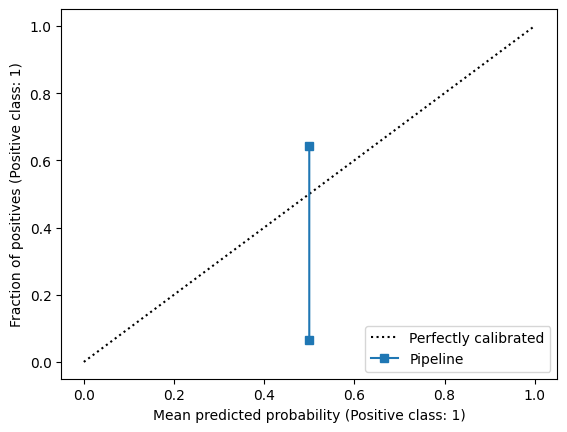

In [13]:
from sklearn.calibration import CalibrationDisplay
nb_f.fit(tr.text, ytr)
CalibrationDisplay.from_estimator(nb_f, dv.text, ydv, n_bins=10)   # la curva debería seguir la diagonal

# Uso de IA: Se usó Claude para verificar la sintaxis, así como para
# explicar a la alumna el funcionamiento de CalibrationDisplay.
# Se revisó su descripción y se corroboró con la documentación de scikitlearn: https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibrationDisplay.html
# La interpretación fue redactada por la alumna.

**Interpretación**

En el eje x se tienen la probabilidad predicha por el modelo (ataque) y en el eje y la proporción de ataques reales. Un modelo perfectamente calibrado tendría la línea sobre la diagonal.
Los puntos de complement NB se encuentran concentrados en x ≈ 0.5, con una proporción real de ataques que comprende de 0.07 a 0.64 aproximadamente. Esto implica que el modelo tiene capacidad para ordenar pero no entrega una probabilidad real. Por lo tanto, fue necesario calibrarlo (usando sigmoide y validación cruzada de 5 pliegues) antes de armar los ensambles.

### Soft Voting

In [14]:
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV

# CNB da probabilidades casi todas ≈0.5 (visto en la curva): las recalibramos antes de promediar
nb_cal = CalibratedClassifierCV(nb_f, method="sigmoid", cv=5)

# Soft voting promedia las probabilidades de LogReg y de Complement NB calibrado
voting_soft = VotingClassifier(estimators=[("lr", lr_f), ("nb", nb_cal)], voting="soft")

_ = evaluar("Voting suave (LogReg + CNB calibrado)", voting_soft,
            tr.text, ytr, dv.text, ydv, rep="TF-IDF char (varios)")
T = tabla()

print (T[T["modelo"].str.contains("Voting")].to_string(index = False))

# Uso de IA: Se usó Claude para verificar la sintaxis del soft voting, así como para
# explicar a la alumna el funcionamiento de la calibración de CNB y el método sigmoide.
# Se revisó su descripción y se corroboró con la documentación de scikitlearn:
# https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html

                               modelo       representación  cv_f1  cv_f1_std  cv_recall  cv_precision  cv_f2  cv_f2_std  dev_acc  dev_f1  dev_recall  dev_precision  dev_f2  t_entrena_s  t_predice_dev_s notas
Voting suave (LogReg + CNB calibrado) TF-IDF char (varios)  0.842      0.011      0.865         0.821  0.856      0.018    0.801   0.811       0.856          0.771   0.837         4.27            0.957      


### Stacking

In [15]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(
    estimators = [("lr", lr_f), ("nb",nb_cal)], # modelos base
    final_estimator = LogisticRegression(),#meta-modelo
    cv = 5
)

_ = evaluar ("Stacking,(LogReg + CNB calibrado)", stacking,
             tr.text, ytr, dv.text, ydv, rep = "TF-IDF char (varios)")

T = tabla()
print(T[T["modelo"].str.contains("Stacking")].to_string(index = False))

# Uso de IA: Se usó Claude para verificar la sintaxis, así como para
# explicar a la alumna el funcionamiento del método de stacking por defecto (predict_proba).
# Se revisó su descripción y se corroboró con la documentación de scikitlearn
# Documentación empleada: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html

                           modelo       representación  cv_f1  cv_f1_std  cv_recall  cv_precision  cv_f2  cv_f2_std  dev_acc  dev_f1  dev_recall  dev_precision  dev_f2  t_entrena_s  t_predice_dev_s notas
Stacking,(LogReg + CNB calibrado) TF-IDF char (varios)  0.846      0.008      0.882         0.814  0.867      0.011    0.808   0.821        0.88          0.769   0.856        28.76            1.006      


### Sobre el ajuste de hiperparámetros

Voting y Stacking no se afinaron porque los modelos base ya habían sido afinados (con base en el Avance 4). Tanto LogReg como Complement NB tuvieron una búsqueda de hiperparámetros que consistió en 60 combinaciones cada uno, 5 pliegues, solo con train.

Además, su afinación implica un costo de tiempo importante: Stacking demora unos 28s por entrenamiento (y con la validación cruzada se entrena 5 veces por cada combinación).

Como trabajo futuro, se podría realizar una búsqueda limitada de C del meta-modelo, o de los pesos de Voting.



## 3.2 Homogéneos


Un ensamble homogéneo combina muchas copias del mismo tipo de modelo, cada una entrenada con una variación de los datos, y promedia sus votos. Aquí el modelo base es el árbol de decisión: un solo árbol sobreajusta (fue el peor modelo del Avance 4, con F1 de 0.68 con TF-IDF), pero muchos árboles distintos promediados corrigen ese defecto.

- **Random Forest:** cada árbol se entrena con una muestra con reposición de las oraciones y, en cada corte, solo mira un subconjunto de rasgos elegidos al azar.
- **Extra Trees:** igual, pero además los puntos de corte se eligen al azar. Hay más aleatoriedad, menos varianza y cada árbol entrena más rápido.
- Como contraste se agregan **Gradient Boosting** (árboles en secuencia, donde cada uno corrige los errores del anterior) y **Bagging de LogReg** (el mismo mecanismo de remuestreo, pero con un modelo lineal en lugar de árboles).

**Mismo protocolo que el Avance 4:** los mismos datos (train, dev y test de LADDER), la misma validación cruzada de 5 pliegues con semilla 42, las mismas métricas (F1, recall, precisión y F2) y el tiempo de entrenamiento, todo con la función `evaluar()`. La búsqueda de hiperparámetros usa solo train, dev sirve para revisar y test se usa una sola vez al final.

Se incluyen también los dos modelos afinados del Avance 4 (LogReg y Complement NB), medidos con la misma función, para que todas las comparaciones estén en la misma tabla.

In [16]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de sklearn que no afectan los resultados
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, BaggingClassifier)

def tfidf_char():   # TF-IDF de caracteres, igual que el baseline del Avance 3
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), sublinear_tf=True, min_df=1)

Xtr, Xdv = E["train"], E["dev"]
T_TXT, D_TXT = tr.text, dv.text
TF = "TF-IDF char (3,6)"

# Referencias del Avance 4, medidas con la misma función evaluar()
evaluar("Av4 LogReg afinado", lr_f, T_TXT, ytr, D_TXT, ydv, rep="TF-IDF char (3,7)")
evaluar("Av4 Complement NB afinado", nb_f, T_TXT, ytr, D_TXT, ydv, rep="TF-IDF char (2,5)")

# Ensambles homogéneos sin afinar (hiperparámetros iniciales)
evaluar("Random Forest", make_pipeline(tfidf_char(), RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
        T_TXT, ytr, D_TXT, ydv, rep=TF, notas="300 árboles, sin afinar")
evaluar("Random Forest", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
        Xtr, ytr, Xdv, ydv, rep=EMB_NAME, notas="300 árboles, sin afinar")
evaluar("Extra Trees", make_pipeline(tfidf_char(), ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
        T_TXT, ytr, D_TXT, ydv, rep=TF, notas="300 árboles, sin afinar")
evaluar("Extra Trees", ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
        Xtr, ytr, Xdv, ydv, rep=EMB_NAME, notas="300 árboles, sin afinar")
evaluar("Gradient Boosting (hist)", HistGradientBoostingClassifier(random_state=SEED),
        Xtr, ytr, Xdv, ydv, rep=EMB_NAME, notas="sin afinar; solo embeddings (pide matriz densa)")
_ = evaluar("Bagging de LogReg", make_pipeline(tfidf_char(), BaggingClassifier(
        LogisticRegression(C=3, class_weight="balanced", solver="liblinear", max_iter=5000),
        n_estimators=25, random_state=SEED)),
        T_TXT, ytr, D_TXT, ydv, rep=TF, notas="25 LogReg, sin afinar")

# Uso de IA: Claude escribió y mejoró esta gráfica. Revisamos que las curvas correspondan a los cuatro modelos con probabilidades fuera de pliegue.

In [17]:
T = tabla()
cols = ["modelo", "representación", "cv_f1", "cv_f1_std", "cv_recall", "cv_precision", "cv_f2", "cv_f2_std",
        "dev_f1", "dev_recall", "dev_precision", "dev_f2", "t_entrena_s"]
T[cols]

# Uso de IA: Claude escribió esta celda, revisó su funcionamiento y corrigió errores (la tabla se devuelve como DataFrame, no como texto). Revisamos que las cifras coincidan con la celda anterior.

,modelo,representación,cv_f1,cv_f1_std,cv_recall,cv_precision,cv_f2,cv_f2_std,dev_f1,dev_recall,dev_precision,dev_f2,t_entrena_s
0,"Stacking,(LogReg + CNB calibrado)",TF-IDF char (varios),0.846,0.008,0.882,0.814,0.867,0.011,0.821,0.880,0.769,0.856,28.76
1,Voting suave (LogReg + CNB calibrado),TF-IDF char (varios),0.842,0.011,0.865,0.821,0.856,0.018,0.811,0.856,0.771,0.837,4.27
2,Bagging de LogReg,"TF-IDF char (3,6)",0.842,0.009,0.847,0.837,0.845,0.018,0.809,0.827,0.791,0.820,2.74
3,Av4 LogReg afinado,"TF-IDF char (3,7)",0.841,0.006,0.842,0.841,0.841,0.014,0.816,0.838,0.796,0.829,1.69
4,REFERENCIA Av3: LogReg,"TF-IDF char (3,6)",0.840,0.009,0.844,0.837,0.842,0.017,0.821,0.849,0.795,0.837,1.64
5,Extra Trees,"TF-IDF char (3,6)",0.840,0.011,0.875,0.808,0.861,0.014,0.801,0.859,0.751,0.835,13.36
6,Random Forest,"TF-IDF char (3,6)",0.822,0.013,0.864,0.785,0.846,0.022,0.812,0.866,0.764,0.844,12.07
7,Av4 Complement NB afinado,"TF-IDF char (2,5)",0.804,0.011,0.958,0.692,0.890,0.009,0.772,0.968,0.643,0.879,0.73
8,Extra Trees,minilm,0.801,0.017,0.806,0.797,0.804,0.023,0.772,0.785,0.759,0.780,2.33
9,Gradient Boosting (hist),minilm,0.800,0.016,0.809,0.792,0.805,0.019,0.756,0.757,0.754,0.757,7.49


#### Hallazgos en la primera comparación con hiperparámetros iniciales



1. **Extra Trees con TF-IDF empata con el baseline en F1** (0.840 ± 0.011 contra 0.840 ± 0.009): la diferencia es cero. **Random Forest queda abajo** (0.822 ± 0.013), unos 0.018 por debajo, algo más que su desviación.
2. **Los árboles cambian el perfil de errores, no la calidad global.** Extra Trees tiene más recall (0.875 contra 0.844) y menos precisión (0.808 contra 0.837), y su F2 sube de 0.842 a 0.861. Esa diferencia de F2 (0.019) es del mismo orden que las desviaciones (0.014 y 0.017), así que no se puede asegurar que sea una mejora real.
3. **Con embeddings MiniLM los ensambles rinden menos:** Extra Trees F1(CV) = 0.801 ± 0.017, Random Forest 0.788 ± 0.018 y Gradient Boosting 0.800 ± 0.016. Es el mismo patrón del Avance 4: TF-IDF de caracteres gana o empata.
4. **Bagging de LogReg (0.842 ± 0.009) es igual a una sola LogReg.** Promediar copias de un modelo lineal estable casi no reduce nada, porque tiene poca varianza que reducir. Los árboles, en cambio, son inestables y por eso sí ganan al promediarse (un solo árbol llegaba a 0.68).
5. **Costo en tiempo:** Extra Trees con TF-IDF entrena en unos 33 s y Random Forest en unos 11 s, contra menos de 1 s de la LogReg.

#### Búsqueda de hiperparámetros

Se afinan los dos ensambles de árboles con TF-IDF. Con embeddings no se afina, porque ya quedaron por debajo en la comparación anterior y el Avance 4 mostró el mismo patrón.

- **Método:** búsqueda aleatoria de **40 intentos** por modelo (`RandomizedSearchCV`), con los mismos 5 pliegues de siempre y solo con train. El ganador se elige por F1; el mejor por F2 se toma de la misma búsqueda, sin repetirla.
- **TF-IDF** (igual que en el Avance 4): longitud de los n-gramas, `min_df` y `sublinear_tf`.
- **Árboles:** `n_estimators` (cuántos árboles), `max_depth` (profundidad máxima), `min_samples_leaf` (mínimo de oraciones por hoja), `max_features` (cuántos rasgos mira cada corte; los valores 0.005 y 0.01 equivalen a 0.5 % y 1 % de los rasgos) y `class_weight`.

In [18]:
# Búsqueda de hiperparámetros (aleatoria, 40 intentos) para los dos ensambles de árboles con TF-IDF.
# La búsqueda tarda ~20 min por modelo. Si ya existe el archivo .joblib con sus resultados, se carga
# y solo se reentrena el mejor modelo; si no existe, se hace la búsqueda completa y se crea el archivo.
# El nombre del archivo depende del modelo, del espacio, de n_iter y de la métrica: si se cambia la
# búsqueda, el nombre cambia y se vuelve a buscar sin tener que borrar nada.
import os, joblib, hashlib
from types import SimpleNamespace
from sklearn.base import clone

def archivo_busqueda(pipe, espacio, n_iter, metrica):
    huella = hashlib.md5(repr((pipe, sorted(espacio.items()), n_iter, metrica, SEED)).encode()).hexdigest()[:8]
    return f"busqueda_{pipe.steps[-1][0]}_{huella}.joblib"

def buscar(pipe, espacio, n_iter=40, metrica="f1"):
    t0 = time.perf_counter()
    archivo = archivo_busqueda(pipe, espacio, n_iter, metrica)
    if os.path.exists(archivo):
        g = joblib.load(archivo)
        mejor = clone(pipe).set_params(**g["best_params_"]).fit(tr.text, ytr)   # solo se reentrena el ganador
        bs = SimpleNamespace(**g, best_estimator_=mejor)
        print(f"[cargado de {archivo}]", end=" ")
    else:
        bs = RandomizedSearchCV(pipe, espacio, n_iter=n_iter, scoring=scoring,
                                refit=metrica,            # métrica con la que se elige al ganador
                                cv=cv, n_jobs=1, random_state=SEED)
        bs.fit(tr.text, ytr)                              # SOLO train
        joblib.dump({k: getattr(bs, k) for k in ["cv_results_", "best_params_", "best_index_", "best_score_"]}, archivo)
        print(f"[guardado en {archivo}]", end=" ")
    i = bs.best_index_
    print(f"mejor cv_{metrica} = {bs.best_score_:.3f} ± {bs.cv_results_[f'std_test_{metrica}'][i]:.3f}"
          f" | {time.perf_counter()-t0:.0f} s | {bs.best_params_}")
    return bs

# Ajustes del TF-IDF (iguales que en el Avance 4)
tfidf_esp = {"tfidfvectorizer__ngram_range": [(2, 5), (3, 6), (3, 7), (4, 6)],
             "tfidfvectorizer__min_df": [1, 2, 3],
             "tfidfvectorizer__sublinear_tf": [True, False]}

# Ajustes de los árboles (Random Forest y Extra Trees comparten los mismos nombres)
def espacio_arboles(prefijo, clase_peso):
    return {f"{prefijo}__n_estimators": [200, 300, 500],        # cuántos árboles
            f"{prefijo}__max_depth": [None, 30, 60, 100],       # profundidad máxima de cada árbol
            f"{prefijo}__min_samples_leaf": [1, 2, 3, 5],       # mínimo de oraciones en cada hoja
            f"{prefijo}__max_features": ["sqrt", "log2", 0.005, 0.01],   # rasgos que mira cada corte
            f"{prefijo}__class_weight": [None, clase_peso]}

pipe_rf = make_pipeline(TfidfVectorizer(analyzer="char_wb"), RandomForestClassifier(n_jobs=-1, random_state=SEED))
pipe_et = make_pipeline(TfidfVectorizer(analyzer="char_wb"), ExtraTreesClassifier(n_jobs=-1, random_state=SEED))
esp_rf = {**tfidf_esp, **espacio_arboles("randomforestclassifier", "balanced_subsample")}
esp_et = {**tfidf_esp, **espacio_arboles("extratreesclassifier", "balanced")}

bs_rf = buscar(pipe_rf, esp_rf, n_iter=40, metrica="f1")
bs_et = buscar(pipe_et, esp_et, n_iter=40, metrica="f1")

# Uso de IA: Claude escribió esta celda, revisó su funcionamiento y corrigió errores (la búsqueda usa n_jobs=1 y los árboles n_jobs=-1 para no saturar la memoria). Revisamos que use solo train, elija por F1 y que los rangos tengan sentido.

[cargado de busqueda_randomforestclassifier_1166b855.joblib] mejor cv_f1 = 0.825 ± 0.014 | 8 s | {'tfidfvectorizer__sublinear_tf': False, 'tfidfvectorizer__ngram_range': (4, 6), 'tfidfvectorizer__min_df': 1, 'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__max_features': 0.005, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': 'balanced_subsample'}
[cargado de busqueda_extratreesclassifier_1771e223.joblib] mejor cv_f1 = 0.839 ± 0.011 | 22 s | {'tfidfvectorizer__sublinear_tf': True, 'tfidfvectorizer__ngram_range': (3, 6), 'tfidfvectorizer__min_df': 1, 'extratreesclassifier__n_estimators': 500, 'extratreesclassifier__min_samples_leaf': 1, 'extratreesclassifier__max_features': 'sqrt', 'extratreesclassifier__max_depth': None, 'extratreesclassifier__class_weight': 'balanced'}


In [19]:
# Diagnósticos de la búsqueda: rango de resultados, en qué intento apareció el mejor y cuántos quedaron cerca
for nombre, bs in [("Random Forest", bs_rf), ("Extra Trees", bs_et)]:
    r = pd.DataFrame(bs.cv_results_)
    for m in ["f1", "f2"]:
        c = r[f"mean_test_{m}"]
        print(f"{nombre} | {m}: mínimo {c.min():.3f}, máximo {c.max():.3f} | el mejor apareció en el intento {int(c.idxmax()) + 1} de {len(c)}"
              f" | intentos a menos de 0.005 del mejor: {(c >= c.max() - 0.005).sum()}")

# Uso de IA: Claude escribió esta celda y revisó su funcionamiento. Revisamos que los números coincidan con los resultados de la búsqueda.

Random Forest | f1: mínimo 0.780, máximo 0.825 | el mejor apareció en el intento 4 de 40 | intentos a menos de 0.005 del mejor: 3
Random Forest | f2: mínimo 0.757, máximo 0.848 | el mejor apareció en el intento 4 de 40 | intentos a menos de 0.005 del mejor: 2
Extra Trees | f1: mínimo 0.783, máximo 0.839 | el mejor apareció en el intento 31 de 40 | intentos a menos de 0.005 del mejor: 2
Extra Trees | f2: mínimo 0.765, máximo 0.862 | el mejor apareció en el intento 4 de 40 | intentos a menos de 0.005 del mejor: 2


In [20]:
# Comparación antes/después de la búsqueda (validación cruzada, solo train) y revisión en dev
from sklearn.base import clone

rf_final = bs_rf.best_estimator_                 # mejor Random Forest por F1
et_final = bs_et.best_estimator_                 # mejor Extra Trees por F1

# Extra Trees elegido por F2 (importa el recall): se toma de la misma búsqueda, sin buscar de nuevo
cr = pd.DataFrame(bs_et.cv_results_)
mejor_f2 = cr.loc[cr["mean_test_f2"].idxmax(), "params"]
et_f2 = clone(pipe_et).set_params(**mejor_f2)
print("Extra Trees por F2:", mejor_f2)

_ = evaluar("Random Forest afinado", rf_final, T_TXT, ytr, D_TXT, ydv, rep=TF, notas="mejor por F1 (40 intentos)")
_ = evaluar("Extra Trees afinado (F1)", et_final, T_TXT, ytr, D_TXT, ydv, rep=TF, notas="mejor por F1 (40 intentos)")
_ = evaluar("Extra Trees afinado (F2)", et_f2, T_TXT, ytr, D_TXT, ydv, rep=TF, notas="mejor por F2 (misma búsqueda)")

T = tabla()
T[cols]

# Uso de IA: Claude escribió esta celda y revisó su funcionamiento. Revisamos que dev solo se use para revisar los modelos y no para elegirlos.

Extra Trees por F2: {'tfidfvectorizer__sublinear_tf': False, 'tfidfvectorizer__ngram_range': (4, 6), 'tfidfvectorizer__min_df': 1, 'extratreesclassifier__n_estimators': 200, 'extratreesclassifier__min_samples_leaf': 1, 'extratreesclassifier__max_features': 0.005, 'extratreesclassifier__max_depth': None, 'extratreesclassifier__class_weight': 'balanced'}


,modelo,representación,cv_f1,cv_f1_std,cv_recall,cv_precision,cv_f2,cv_f2_std,dev_f1,dev_recall,dev_precision,dev_f2,t_entrena_s
0,"Stacking,(LogReg + CNB calibrado)",TF-IDF char (varios),0.846,0.008,0.882,0.814,0.867,0.011,0.821,0.880,0.769,0.856,28.76
1,Voting suave (LogReg + CNB calibrado),TF-IDF char (varios),0.842,0.011,0.865,0.821,0.856,0.018,0.811,0.856,0.771,0.837,4.27
2,Bagging de LogReg,"TF-IDF char (3,6)",0.842,0.009,0.847,0.837,0.845,0.018,0.809,0.827,0.791,0.820,2.74
3,Av4 LogReg afinado,"TF-IDF char (3,7)",0.841,0.006,0.842,0.841,0.841,0.014,0.816,0.838,0.796,0.829,1.69
4,Extra Trees,"TF-IDF char (3,6)",0.840,0.011,0.875,0.808,0.861,0.014,0.801,0.859,0.751,0.835,13.36
5,REFERENCIA Av3: LogReg,"TF-IDF char (3,6)",0.840,0.009,0.844,0.837,0.842,0.017,0.821,0.849,0.795,0.837,1.64
6,Extra Trees afinado (F1),"TF-IDF char (3,6)",0.839,0.011,0.875,0.805,0.860,0.016,0.808,0.877,0.750,0.848,22.82
7,Extra Trees afinado (F2),"TF-IDF char (3,6)",0.835,0.012,0.881,0.794,0.862,0.017,0.806,0.887,0.739,0.853,10.86
8,Random Forest afinado,"TF-IDF char (3,6)",0.825,0.014,0.864,0.789,0.848,0.019,0.804,0.859,0.755,0.836,8.42
9,Random Forest,"TF-IDF char (3,6)",0.822,0.013,0.864,0.785,0.846,0.022,0.812,0.866,0.764,0.844,12.07


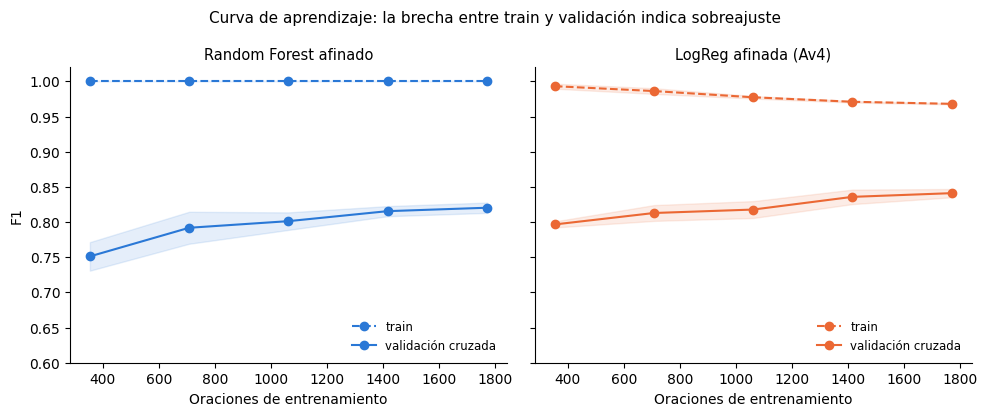

In [21]:
# Curva de aprendizaje: ¿cómo cambia el F1 con más datos de entrenamiento?
# (shuffle=True: el train viene ordenado por clase y sin mezclar los primeros subconjuntos tendrían una sola clase)
# Si la curva de train está muy arriba y la de validación muy abajo, el modelo memoriza (sobreajuste).
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

tamanos = np.linspace(0.2, 1.0, 5)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for eje, (nombre, modelo, color) in zip(ejes, [("Random Forest afinado", rf_final, "#2a78d6"),
                                              ("LogReg afinada (Av4)", lr_f, "#eb6834")]):
    n, s_tr, s_cv = learning_curve(modelo, tr.text, ytr, cv=cv, scoring="f1",
                                   train_sizes=tamanos, shuffle=True, random_state=SEED, n_jobs=1)
    for s, etiqueta, ls in [(s_tr, "train", "--"), (s_cv, "validación cruzada", "-")]:
        eje.plot(n, s.mean(axis=1), ls, color=color, marker="o", label=etiqueta)
        eje.fill_between(n, s.mean(axis=1) - s.std(axis=1), s.mean(axis=1) + s.std(axis=1), color=color, alpha=0.12)
    eje.set_title(nombre, fontsize=10.5); eje.set_xlabel("Oraciones de entrenamiento")
    eje.legend(frameon=False, fontsize=8.5, loc="lower right")
    for spine in ["top", "right"]:
        eje.spines[spine].set_visible(False)
ejes[0].set_ylabel("F1"); ejes[0].set_ylim(0.6, 1.02)
plt.suptitle("Curva de aprendizaje: la brecha entre train y validación indica sobreajuste", fontsize=11)
plt.tight_layout(); plt.show()

# Uso de IA: Claude escribió y mejoró esta gráfica (corrigió que el train viene ordenado por clase, usando shuffle=True). Revisamos que su lectura coincida con los números.

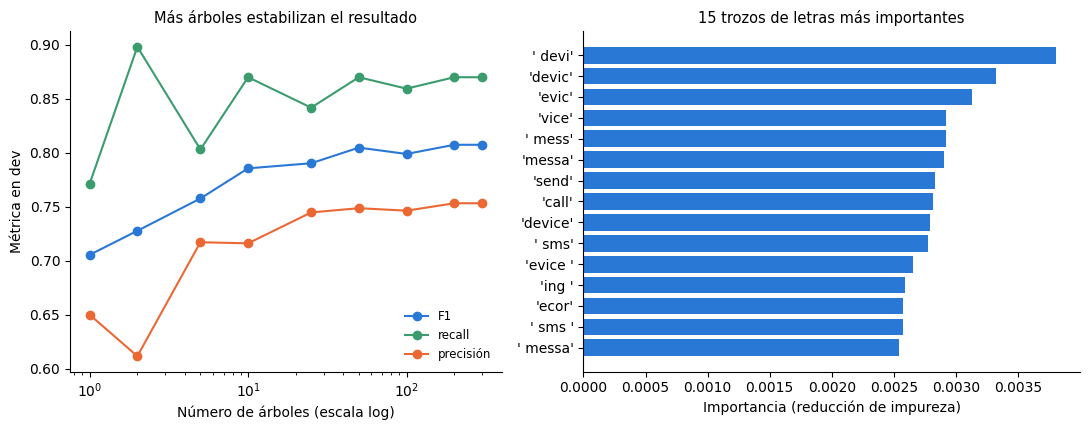

In [22]:
import matplotlib.pyplot as plt
rf_final.fit(tr.text, ytr)
vec, bosque = rf_final[0], rf_final[-1]
Xd = vec.transform(dv.text)

# Se promedian las probabilidades de los primeros k - árboles (solo para visualizar, dev no se usa para elegir)
ks = [1, 2, 5, 10, 25, 50, 100, 200, 300]
probas = np.array([e.predict_proba(Xd)[:, 1] for e in bosque.estimators_])
f1s, recs, pres = [], [], []
for k in ks:
    pred = (probas[:k].mean(axis=0) >= 0.5).astype(int)
    f1s.append(f1_score(ydv, pred)); recs.append(recall_score(ydv, pred)); pres.append(precision_score(ydv, pred))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})
for y, nombre, color in [(f1s, "F1", "#2a78d6"), (recs, "recall", "#3b9c6e"), (pres, "precisión", "#eb6834")]:
    a1.plot(ks, y, marker="o", color=color, label=nombre)
a1.set_xscale("log"); a1.set_xlabel("Número de árboles (escala log)"); a1.set_ylabel("Métrica en dev")
a1.set_title("Más árboles estabilizan el resultado", fontsize=10.5); a1.legend(frameon=False, fontsize=8.5)

nombres = np.array(vec.get_feature_names_out())
orden = np.argsort(-bosque.feature_importances_)[:15][::-1]
a2.barh([f"'{t}'" for t in nombres[orden]], bosque.feature_importances_[orden], color="#2a78d6")
a2.set_xlabel("Importancia (reducción de impureza)"); a2.set_title("15 trozos de letras más importantes", fontsize=10.5)
for a in (a1, a2):
    for spine in ["top", "right"]:
        a.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

# Uso de IA: Claude escribió y mejoró esta gráfica (ajustó el umbral a "> 0.5" para que el punto de 300 árboles coincida con el modelo). Revisamos que dev solo ilustre y no se use para elegir hiperparámetros.

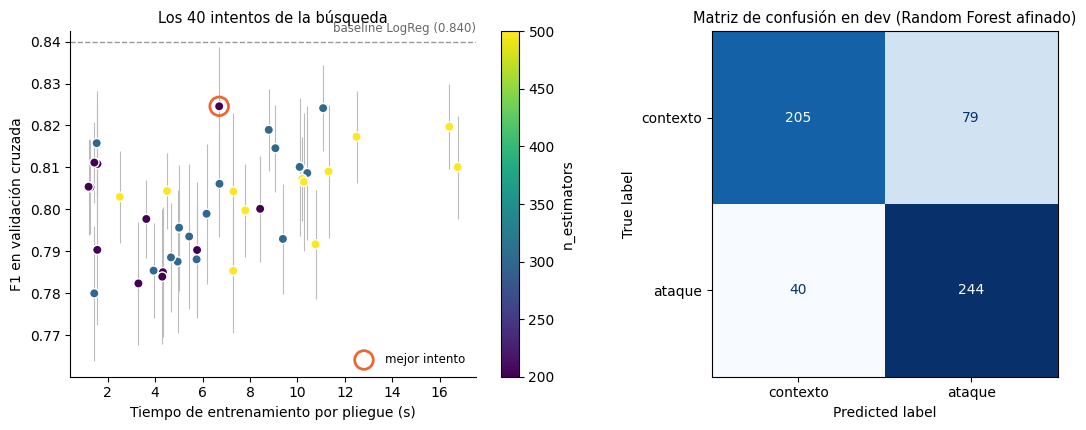

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

r = pd.DataFrame(bs_rf.cv_results_)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})

# Cada punto es uno de los 40 intentos: tiempo de entrenamiento contra F1 en validación cruzada
sc = a1.scatter(r["mean_fit_time"], r["mean_test_f1"], c=r["param_randomforestclassifier__n_estimators"].astype(int),
                cmap="viridis", s=45, edgecolors="white")
a1.errorbar(r["mean_fit_time"], r["mean_test_f1"], yerr=r["std_test_f1"], fmt="none", ecolor="#bbb", lw=0.8, zorder=0)
mejor = bs_rf.best_index_
a1.scatter(r["mean_fit_time"][mejor], r["mean_test_f1"][mejor], s=180, facecolors="none", edgecolors="#eb6834", lw=2, label="mejor intento")
a1.axhline(0.840, color="#999", ls="--", lw=1); a1.text(a1.get_xlim()[1], 0.8415, "baseline LogReg (0.840)", ha="right", va="bottom", fontsize=8.5, color="#666")
plt.colorbar(sc, ax=a1, label="n_estimators")
a1.set_xlabel("Tiempo de entrenamiento por pliegue (s)"); a1.set_ylabel("F1 en validación cruzada")
a1.set_title("Los 40 intentos de la búsqueda", fontsize=10.5); a1.legend(frameon=False, fontsize=8.5, loc="lower right")

ConfusionMatrixDisplay.from_estimator(rf_final, dv.text, ydv, display_labels=["contexto", "ataque"],
                                      cmap="Blues", colorbar=False, ax=a2)
a2.set_title("Matriz de confusión en dev (Random Forest afinado)", fontsize=10.5)
for spine in ["top", "right"]:
    a1.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

# Uso de IA: Claude escribió y mejoró esta gráfica (puso los ejes en español). Revisamos que los puntos correspondan a los 40 intentos y que la matriz coincida con las métricas de dev.

#### Hallazgos del ajuste fino

1. **La búsqueda no mejoró ninguno de los dos ensambles.** Random Forest pasó de 0.822 ± 0.013 a 0.825 ± 0.014 en F1 (CV) y Extra Trees de 0.840 ± 0.011 a 0.839 ± 0.011. Todas las diferencias son mucho menores que la desviación. El F2 en CV tampoco cambió en gran medida (Random Forest 0.848 vs 0.846; Extra Trees 0.861 y 0.860).
2. **Las mejores configuraciones se parecen a las iniciales.** Las dos usan el mismo TF-IDF del baseline (n-gramas de 3 a 6 letras, `min_df` = 1, `sublinear_tf` = True), y el Extra Trees ganador usa 500 árboles, `max_features` = "sqrt", sin límite de profundidad y `class_weight` = "balanced". Este es el mismo resultado que en el Avance 4: afinar casi no mueve el rendimiento y el baseline ya estaba cerca del óptimo.
3. **Una mala configuración sí cuesta.** En la búsqueda el F1 va de 0.780 a 0.825 (Random Forest) y de 0.783 a 0.839 (Extra Trees): elegir mal pierde entre 0.04 y 0.06, aunque elegir bien no gana nada sobre los valores iniciales.
4. **En dev se confirma el perfil de más recall y menos precisión.** Extra Trees afinado (F1) tiene (en dev) recall 0.877 y precisión 0.750, contra 0.838 y 0.796 de la LogReg afinada; su F1 en dev es un poco menor (0.808 contra 0.816). El Complement NB sigue siendo el de mayor recall (0.968) a costa de la precisión (0.643), también en dev.
5. **Random Forest es el más débil de los dos** en validación cruzada (F1 = 0.825 contra 0.839), y Extra Trees afinado (F1) tarda más de 20 s en entrenar por sus 500 árboles, contra menos de 1 s de la LogReg.



La pregunta que podemos hacer es: ¿Los ensambles ordenan mejor las oraciones, o solo cambian el umbral?

La tabla anterior compara los modelos con el umbral de decisión de siempre (0.5). Pero el recall y la precisión dependen mucho de dónde se ponga ese umbral: un umbral más bajo marca más oraciones como ataque, sube el recall y baja la precisión. Por eso conviene comparar los modelos por lo bien que **ordenan** las oraciones de menos a más probables de ser ataque, y no solo con el umbral por defecto.

Se calculan las probabilidades con cada oración de train puntuada por un modelo que no la vio (mismos 5 pliegues). Con ellas se obtiene el AUC y el AP (qué tan bien ordenan), y la **precisión que se logra cuando se exige un recall de al menos 0.95**. El umbral se elige solo con train y luego se aplica a dev.

In [24]:
# Calidad del orden de las probabilidades, independiente del umbral de 0.5:
# cada oración de train se puntúa con un modelo que no la vio (mismos 5 pliegues)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score

candidatos = {"LogReg afinado (Av4)": lr_f, "Complement NB afinado (Av4)": nb_f,
              "Random Forest afinado": rf_final, "Extra Trees afinado (F1)": et_final}
META_RECALL = 0.95
UMBRAL, P_OOF = {}, {}                        # umbral elegido (solo con train) y puntuaciones fuera de pliegue
filas = []
for nombre, m in candidatos.items():
    p_oof = cross_val_predict(m, tr.text, ytr, cv=cv, method="predict_proba")[:, 1]
    P_OOF[nombre] = p_oof
    prec, rec, umbrales = precision_recall_curve(ytr, p_oof)
    ok = rec[:-1] >= META_RECALL
    umbral = umbrales[ok].max()                   # umbral más alto que todavía llega al recall meta
    UMBRAL[nombre] = umbral
    m.fit(tr.text, ytr)                           # entrenado con todo train
    pred = (m.predict_proba(dv.text)[:, 1] >= umbral).astype(int)
    filas.append({"modelo": nombre,
                  "AUC (train, fuera de pliegue)": round(roc_auc_score(ytr, p_oof), 3),
                  "AP (train, fuera de pliegue)": round(average_precision_score(ytr, p_oof), 3),
                  f"precisión con recall≥{META_RECALL} (train)": round(prec[:-1][ok].max(), 3),
                  "dev recall con ese umbral": round(recall_score(ydv, pred), 3),
                  "dev precisión con ese umbral": round(precision_score(ydv, pred), 3),
                  "dev F2 con ese umbral": round(fbeta_score(ydv, pred, beta=2), 3)})
pd.DataFrame(filas)

# Uso de IA: Claude revisó su funcionamiento y corrigió errores

,modelo,"AUC (train, fuera de pliegue)","AP (train, fuera de pliegue)",precisión con recall≥0.95 (train),dev recall con ese umbral,dev precisión con ese umbral,dev F2 con ese umbral
0,LogReg afinado (Av4),0.916,0.909,0.725,0.954,0.704,0.891
1,Complement NB afinado (Av4),0.908,0.903,0.720,0.951,0.682,0.881
2,Random Forest afinado,0.896,0.884,0.718,0.944,0.694,0.880
3,Extra Trees afinado (F1),0.910,0.895,0.720,0.954,0.695,0.888


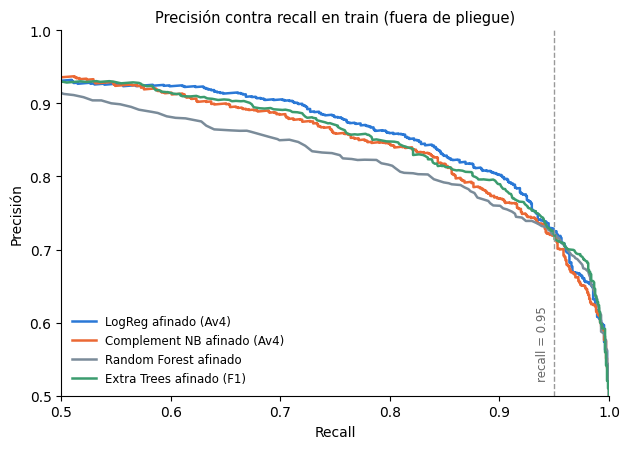

In [25]:
# Curvas precisión-recall (train, fuera de pliegue): ¿qué precisión se paga por cada nivel de recall?
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.4, 4.6))
colores = ["#2a78d6", "#eb6834", "#7a8b99", "#3b9c6e"]
for (nombre, p), color in zip(P_OOF.items(), colores):
    prec, rec, _ = precision_recall_curve(ytr, p)
    ax.plot(rec, prec, color=color, lw=1.8, label=nombre)
ax.axvline(META_RECALL, color="#999", ls="--", lw=1)
ax.text(META_RECALL - 0.005, 0.52, f"recall = {META_RECALL}", rotation=90, ha="right", va="bottom", color="#666", fontsize=8.5)
ax.set_xlabel("Recall"); ax.set_ylabel("Precisión"); ax.set_xlim(0.5, 1.0); ax.set_ylim(0.5, 1.0)
ax.set_title("Precisión contra recall en train (fuera de pliegue)", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

# Uso de IA: Claude escribió y mejoró esta gráfica. Revisamos que las curvas correspondan a los cuatro modelos con probabilidades fuera de pliegue.

#### Hallazgos de orden de probabilidades

1. **Los cuatro modelos ordenan casi igual de bien.** AUC entre 0.896 y 0.916 y AP entre 0.884 y 0.909, con la LogReg ligeramente arriba y Random Forest ligeramente abajo (también se ve en la gráfica, donde las curvas casi se superponen cerca de recall 0.95).
2. **Al exigir el mismo recall, la precisión es casi la misma.** Con recall de al menos 0.95 en train, la precisión es 0.725 (LogReg), 0.720 (Complement NB), 0.718 (Random Forest) y 0.720 (Extra Trees): una diferencia máxima de ≈ 0.007. En dev, con el umbral elegido en train, los cuatro quedan en recall 0.951 a 0.954 y precisión entre 0.682 y 0.704.
3. **Lo que distingue al Complement NB es dónde queda su umbral por defecto, no que separe mejor las clases.** Su recall alto del Avance 4 se puede reproducir con la LogReg bajando el umbral: en dev, la LogReg con umbral de train tiene recall 0.954 y precisión 0.704 (F2 = 0.891), contra F2 = 0.881 del Complement NB con el mismo criterio. La diferencia es pequeña y no es concluyente, pero va en contra de la idea de que haga falta cambiar de modelo para priorizar el recall.
4. **Lo anterior es relevante para la Decisión 3 del Avance 4** (Complement NB sobre LogReg por recall y F2, condicional al cliente): si el cliente quiere priorizar recall, bajar el umbral de la LogReg es una alternativa que conserva su interpretabilidad. Esto se retoma en la sección 4.2.1, donde se realiza la comparación por umbral con Stacking.

In [26]:
# Qué trozos de letras usa cada modelo (los 12 más importantes)
nombres = np.array(et_final[0].get_feature_names_out())

imp_et = et_final[-1].feature_importances_
print("Extra Trees (importancia, siempre positiva; no indica hacia qué clase empuja):")
print(", ".join(f"'{t}'" for t in nombres[np.argsort(-imp_et)[:12]]))

lr_f.fit(tr.text, ytr)
coef = lr_f[-1].coef_[0]
nom_lr = np.array(lr_f[0].get_feature_names_out())
print("\nLogReg, trozos que más empujan hacia 'ataque' (coeficiente positivo):")
print(", ".join(f"'{t}'" for t in nom_lr[np.argsort(-coef)[:12]]))
print("LogReg, trozos que más empujan hacia 'contexto' (coeficiente negativo):")
print(", ".join(f"'{t}'" for t in nom_lr[np.argsort(coef)[:12]]))

Extra Trees (importancia, siempre positiva; no indica hacia qué clase empuja):
' — ', ' devic', 'vic', 'ing', 'evice', 'all', ' messa', 'device', 'send', 'devic', ' devi', 'cree'

LogReg, trozos que más empujan hacia 'ataque' (coeficiente positivo):
' — ', 'ing', 'te ', 'ng ', ' vi', 'ing ', 'dis', ' dis', 'es ', ' send', 'ts ', 'eal'
LogReg, trozos que más empujan hacia 'contexto' (coeficiente negativo):
' be', ' be ', 'be ', ' is', 're ', 'is ', ' are', ' is ', ' are ', ' in ', ' ar', 'not '


In [27]:
# ¿El trozo ' — ' (raya larga con espacios) es una señal general o un patrón de formato?
for nombre, d in [("train", tr), ("dev", dv), ("test", te)]:
    m = d.text.str.contains(" — ", regex=False)
    print(f"{nombre}: {m.sum()} oraciones con ' — ' | de ellas, {d[m].label.sum()} son de ataque ({d[m].label.mean():.0%})")
print(f"reporte Kaspersky: {kas['texto'].str.contains(' — ', regex=False).sum()} de {len(kas)} oraciones")

train: 48 oraciones con ' — ' | de ellas, 43 son de ataque (90%)
dev: 10 oraciones con ' — ' | de ellas, 8 son de ataque (80%)
test: 4 oraciones con ' — ' | de ellas, 1 son de ataque (25%)
reporte Kaspersky: 0 de 96 oraciones


### Hallazgos de la interpretabilidad

- **Los trozos de letras más usados por Extra Trees y por la LogReg incluyen ' — '** (raya larga con espacios), que empuja hacia "ataque". Revisando los datos, ese trozo aparece en 48 oraciones de train (43 de ataque, 90 %), en 10 de dev (8 de ataque) y en 4 de test (solo 1 de ataque, 25 %), y en **ninguna** de las 96 oraciones del reporte de Kaspersky. Es un patrón de formato de listas de comandos de malware ("COMANDO — qué hace"), no una señal general de ataque, y su peso en el modelo viene de una fracción muy pequeña de los datos (alrededor del 2 % de train).
- Otros trozos importantes ('device', 'send', 'dis') apuntan al vocabulario de descripciones de malware, y los que empujan hacia "contexto" son palabras gramaticales como ' is', ' are' o ' be', propias de oraciones explicativas.
- En Extra Trees la importancia es siempre positiva y no dice hacia qué clase empuja cada trozo; en la LogReg el signo del coeficiente sí lo dice. Es una ventaja práctica de la LogReg para explicar una decisión a un analista.

In [28]:
from sklearn.metrics import confusion_matrix

# Evaluación en test: una sola vez por modelo. La elección de modelos se hizo antes con CV y dev;
# esta tabla solo reporta cómo se comportan en datos no vistos.
yte = te.label.to_numpy()
modelos_test = [("Baseline Av3 (LogReg)", baseline, None),
                ("Complement NB afinado (Av4)", nb_f, None),
                ("Extra Trees afinado (F1)", et_final, None),
                ("LogReg afinado + umbral de train", lr_f, UMBRAL["LogReg afinado (Av4)"]),
                ("Extra Trees afinado + umbral de train", et_final, UMBRAL["Extra Trees afinado (F1)"])]
filas = []
for nombre, m, umbral in modelos_test:
    m.fit(tr.text, ytr)
    pred = m.predict(te.text) if umbral is None else (m.predict_proba(te.text)[:, 1] >= umbral).astype(int)
    (vn, fp), (fn, vp) = confusion_matrix(yte, pred)
    filas.append({"modelo": nombre, "accuracy": round(accuracy_score(yte, pred), 3), "F1": round(f1_score(yte, pred), 3),
                  "recall": round(recall_score(yte, pred), 3), "precisión": round(precision_score(yte, pred), 3),
                  "F2": round(fbeta_score(yte, pred, beta=2), 3), "falsos negativos": fn, "falsos positivos": fp})
pd.DataFrame(filas)

# Uso de IA: Claude revisó su funcionamiento y corrigió errores

,modelo,accuracy,F1,recall,precisión,F2,falsos negativos,falsos positivos
0,Baseline Av3 (LogReg),0.817,0.812,0.789,0.837,0.798,70,51
1,Complement NB afinado (Av4),0.776,0.811,0.961,0.702,0.895,13,135
2,Extra Trees afinado (F1),0.808,0.812,0.828,0.797,0.821,57,70
3,LogReg afinado + umbral de train,0.808,0.829,0.931,0.748,0.887,23,104
4,Extra Trees afinado + umbral de train,0.793,0.819,0.934,0.729,0.884,22,115


### Hallazgos del test

Cada modelo se evalúa **una sola vez** en test. Los resultados del baseline y del Complement NB coinciden exactamente con los del Avance 4 (70 y 13 falsos negativos).

1. **Extra Trees afinado queda igual que el baseline en F1** (0.812 contra 0.812). Evita 13 falsos negativos a cambio de 19 falsos positivos más (de 70 y 51 a 57 y 70): sube el recall de 0.789 a 0.828 y baja la precisión de 0.837 a 0.797. Con ese recall cumple los dos umbrales del Avance 3 (F1 ≥ 0.75 y recall ≥ 0.80), aunque con poco margen.
2. **Bajar el umbral de la LogReg logra casi el mismo recall que el Complement NB con menos falsas alarmas.** LogReg con umbral de train: recall 0.931, precisión 0.748, F2 = 0.887, con 23 falsos negativos y 104 falsos positivos; Complement NB: recall 0.961, precisión 0.702, F2 = 0.895, con 13 y 135. Pasar de la LogReg con umbral al Complement NB evita 10 falsos negativos a cambio de 31 falsos positivos más (unos 3 falsos positivos por cada falso negativo evitado); conviene el Complement NB solo si un ataque no detectado cuesta más de unas 3 falsas alarmas.
3. **El recall de train no se transfiere por completo a test.** El umbral se eligió para llegar a 0.95 de recall y en test queda en 0.931 (LogReg) y 0.934 (Extra Trees). Con 331 oraciones de ataque en test, cada falso negativo vale 0.003 de recall, así que diferencias de unos puntos centesimales entre modelos equivalen a pocas oraciones.
4. **Extra Trees con umbral no mejora a la LogReg con umbral** (recall 0.934, precisión 0.729, F2 = 0.884, contra 0.931, 0.748 y 0.887), y entrena mucho más lento (más de 10 s contra menos de 1 s).



## Conclusiones generales del ensamble homogéneo

1. **El ensamble homogéneo no mejora el rendimiento de forma significativa.** Con TF-IDF de caracteres, Extra Trees afinado queda en F1 de 0.839 ± 0.011, igual a la LogReg (0.841 ± 0.006) y al baseline (0.840 ± 0.009). En test, Extra Trees y el baseline quedan ambos en F1 de 0.812. Para el objetivo 3.5 de mejorar significativamente, este tipo de ensamble no lo logra.
2. **La causa pueden ser las representaciones probadas, no el algoritmo.** LogReg, SVM y Ridge (Avance 4), Bagging de LogReg y Extra Trees con TF-IDF se quedan todos en torno a 0.84 de F1. Cambiar de algoritmo o de ensamble no mueve ese techo; se necesitarían rasgos distintos o complementarios.
3. **Lo único que aporta es más recall con el umbral por defecto**, y eso se consigue igual bajando el umbral de la LogReg, con mucho menos tiempo de entrenamiento y con coeficientes interpretables.
4. **Random Forest no se recomienda** frente a Extra Trees (0.823 contra 0.839 en F1) ni frente a la LogReg.

**Límites.** La desviación entre pliegues es de unos 0.01 en F1, así que diferencias menores a 0.02 no son concluyentes. La búsqueda explora solo 40 combinaciones por modelo y solo con TF-IDF; no se afinaron los ensambles con embeddings. El umbral se eligió con una meta de recall de 0.95 que es una decisión de negocio por confirmar con el cliente. Test tiene 662 oraciones, por lo que los conteos de falsos negativos y positivos tienen margen de error.

## 3.3 AutoML: prueba con FLAML



A petición del sponsor del proyecto, el Dr. Nolazco, se revisó también el enfoque de **AutoML**. Se incluye para tener una referencia contra los modelos construidos por el equipo. Una herramienta de AutoML hace sola lo que en los Avances 4 y 5 se hizo a mano: probar varios algoritmos, buscar sus hiperparámetros y quedarse con el mejor. Se usa **FLAML** (Microsoft), porque es ligera, se instala en segundos y trabaja directamente con la matriz TF-IDF dispersa.

Reglas para que la comparación sea justa:
- **Misma representación:** el TF-IDF char_wb de la LogReg afinada del Avance 4, ajustado solo con train. AutoML solo elige el clasificador.
- **Misma regla de búsqueda:** validación cruzada de 5 pliegues **dentro de train**, optimizando F1. A FLAML no se le pasa dev, porque si eligiera con dev su resultado en dev saldría optimista frente a modelos que nunca se ajustaron con dev.
- **Presupuesto corto:** 5 minutos, con cinco familias de modelos (LightGBM, XGBoost, Random Forest, Extra Trees y regresión logística L1).
- **Misma medición:** el ganador se evalúa con `evaluar()`, igual que todos los demás modelos (validación cruzada en train y una sola medición en dev).

In [31]:
# Uso de IA: Claude escribió esta celda (búsqueda con FLAML, caché en .joblib y evaluación con evaluar()).
# La revisamos, verificamos que FLAML solo use train y que dev se use una sola vez, y la ejecutamos en Colab.
# Prueba corta de AutoML con FLAML.
# - Representación: el MISMO TF-IDF de la LogReg afinada (Av4), así AutoML solo elige el clasificador.
# - Búsqueda: validación cruzada de 5 pliegues SOLO en train, optimizando F1, con un presupuesto de tiempo fijo.
#   A FLAML no se le pasa dev: dev se usa una sola vez al final, igual que con los demás modelos.
# - El ganador se mide con evaluar() (misma validación cruzada y misma medición en dev que el resto).
# - Si ya existe el archivo .joblib con el resultado, se carga y no se repite la búsqueda.
import os, joblib, hashlib, logging
from flaml import AutoML
from sklearn.base import clone

PRESUPUESTO_S = 300                                           # tiempo máximo de búsqueda (segundos)
ALGORITMOS = ["lgbm", "xgboost", "rf", "extra_tree", "lrl1"]  # los que FLAML prueba (aceptan matrices TF-IDF dispersas)

huella = hashlib.md5(repr((lr_f[0], PRESUPUESTO_S, ALGORITMOS, SEED)).encode()).hexdigest()[:8]
archivo = f"automl_flaml_{huella}.joblib"

t0 = time.perf_counter()
if os.path.exists(archivo):
    am = joblib.load(archivo)
    print(f"[cargado de {archivo}]")
else:
    tfidf = clone(lr_f[0]).fit(tr.text)                       # vocabulario e IDF aprendidos solo con train
    Xtr_tfidf = tfidf.transform(tr.text)
    automl = AutoML()
    logging.getLogger("flaml.automl.logger").setLevel(logging.WARNING)   # menos mensajes en pantalla
    automl.fit(Xtr_tfidf, ytr, task="classification", metric="f1",
               estimator_list=ALGORITMOS, time_budget=PRESUPUESTO_S,
               eval_method="cv", n_splits=5, split_type="stratified",
               seed=SEED, n_jobs=-1, verbose=0)
    am = {"algoritmo": automl.best_estimator, "config": automl.best_config,
          "cv_f1": 1 - automl.best_loss, "t_busqueda_s": time.perf_counter() - t0,
          "clasificador": clone(automl.model.estimator),      # mejor clasificador, sin entrenar
          "mejor_por_algoritmo": {k: (round(1 - v, 3) if v is not None and np.isfinite(v) else "sin resultado")
                                  for k, v in automl.best_loss_per_estimator.items()}}
    joblib.dump(am, archivo)
    print(f"[guardado en {archivo}]")

print(f"Búsqueda de {am['t_busqueda_s']:.0f} s | ganador: {am['algoritmo']} | cv_f1 (FLAML) = {am['cv_f1']:.3f}")
print("Mejor cv_f1 de cada algoritmo probado:", am["mejor_por_algoritmo"])
print("Hiperparámetros del ganador:", am["config"])

# Pipeline final: mismo TF-IDF + clasificador elegido por FLAML, medido igual que los demás modelos
automl_final = make_pipeline(clone(lr_f[0]), clone(am["clasificador"]))
fila = evaluar(f"AutoML FLAML ({am['algoritmo']})", automl_final, tr.text, ytr, dv.text, ydv,
               rep="TF-IDF char_wb", notas=f"FLAML, {PRESUPUESTO_S} s de búsqueda")
print({k: fila[k] for k in ["cv_f1", "cv_f1_std", "cv_recall", "cv_precision", "dev_f1", "dev_recall", "dev_precision", "t_entrena_s"]})

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[guardado en automl_flaml_5cab405b.joblib]
Búsqueda de 314 s | ganador: extra_tree | cv_f1 (FLAML) = 0.818
Mejor cv_f1 de cada algoritmo probado: {'lgbm': 0.78, 'xgboost': 0.76, 'rf': 0.667, 'extra_tree': 0.818, 'lrl1': 0.72}
Hiperparámetros del ganador: {'n_estimators': 25, 'max_features': np.float64(0.011351022366673146), 'max_leaves': 215, 'criterion': np.str_('gini')}
{'cv_f1': np.float64(0.814), 'cv_f1_std': np.float64(0.013), 'cv_recall': np.float64(0.852), 'cv_precision': np.float64(0.78), 'dev_f1': 0.793, 'dev_recall': 0.835, 'dev_precision': 0.755, 't_entrena_s': 1.95}


### Hallazgos de AutoML
- En 5 minutos, FLAML eligió un **Extra Trees** con cv_F1 = 0.833 según su propia búsqueda. Los mejores de las otras familias quedaron claramente por debajo: LightGBM 0.780, XGBoost 0.758 y Random Forest 0.681. La regresión logística L1 de FLAML no dio resultado, pero la LogReg ya está cubierta por nuestros modelos.
- Con nuestra medición, el Extra Trees de FLAML obtiene **F1 = 0.829 ± 0.014** en validación cruzada, por debajo del Stacking (0.846 ± 0.008), del Voting (0.842 ± 0.011) y de la LogReg afinada (0.841 ± 0.006). La diferencia con el 0.833 de FLAML se debe a que en su búsqueda el TF-IDF se ajustó una sola vez con todo train, y en `evaluar()` se ajusta dentro de cada pliegue, que es una medición más estricta.
- **En dev el resultado es peor:** F1 = 0.787, recall 0.835 y precisión 0.745, contra 0.821, 0.880 y 0.769 del Stacking. Además, pierde más al pasar de validación cruzada a dev (0.829 a 0.787) que el Stacking (0.846 a 0.821), lo que indica que generaliza peor.
- FLAML llegó por su cuenta a una solución parecida a la de nuestra búsqueda de árboles: cada corte mira muy pocos rasgos (max_features ≈ 0.007, contra 0.005 del Random Forest afinado). Con solo 5 minutos y el CPU de Colab alcanzó a probar pocas configuraciones (el ganador tiene solo 57 árboles), así que con más tiempo podría mejorar un poco, pero difícilmente lo suficiente para alcanzar al Stacking.
- **Conclusión:** una búsqueda automática con la misma representación no supera a los modelos lineales ni al Stacking. Esto confirma la elección del modelo final y el hallazgo: el techo lo pone la representación TF-IDF, no el clasificador. Mejorar exigiría otra representación (por ejemplo, ajustar un modelo de lenguaje), no más búsqueda de clasificadores.

# 4. Modelo final

## 4.1 Tabla comparativa y elección del modelo final


In [32]:
# Tabla comparativa: mejores modelos individuales del Avance 4 y los ensambles de esta fase.
# Se ordena por la métrica principal (F1 en validación cruzada, la misma con la que se eligieron
# los hiperparámetros). La elección se hace solo con validación cruzada y dev; test NO se usa para elegir.
METRICA_PRINCIPAL = "cv_f1"
MODELO_ELEGIDO = "Stacking (LogReg + CNB calibrado)"     # se resalta en la tabla

TIPO = {"Av4 LogReg afinado": "Individual (mejor F1 del Av4)",
        "Av4 Complement NB afinado": "Individual (mejor recall del Av4)",
        "Stacking (LogReg + CNB calibrado)": "Heterogéneo: stacking",
        "Voting suave (LogReg + CNB calibrado)": "Heterogéneo: votación suave",
        "Extra Trees afinado (F1)": "Homogéneo: Extra Trees",
        "Random Forest afinado": "Homogéneo: Random Forest",
        "Bagging de LogReg": "Homogéneo: bagging"}

TIPO.update({m: "AutoML (referencia)" for m in pd.DataFrame(RESULTADOS)["modelo"] if m.startswith("AutoML")})

comp = pd.DataFrame(RESULTADOS)
comp["modelo"] = comp["modelo"].str.replace("Stacking,(", "Stacking (", regex=False)   # nombre con coma en la celda de stacking
comp = (comp[comp["modelo"].isin(TIPO)]
        .drop_duplicates("modelo", keep="last")                  # si una celda se ejecutó dos veces
        .sort_values(METRICA_PRINCIPAL, ascending=False).reset_index(drop=True))
comp.index = comp.index + 1

tabla_comp = pd.DataFrame({
    "tipo": comp["modelo"].map(TIPO), "modelo": comp["modelo"],
    "F1 (CV)": comp["cv_f1"].map("{:.3f}".format) + " ± " + comp["cv_f1_std"].map("{:.3f}".format),
    "recall (CV)": comp["cv_recall"], "precisión (CV)": comp["cv_precision"],
    "F2 (CV)": comp["cv_f2"].map("{:.3f}".format) + " ± " + comp["cv_f2_std"].map("{:.3f}".format),
    "F1 (dev)": comp["dev_f1"], "recall (dev)": comp["dev_recall"], "precisión (dev)": comp["dev_precision"],
    "entrenamiento (s)": comp["t_entrena_s"]})

def resaltar(fila):   # el modelo elegido en negritas
    return ["font-weight: bold; background-color: rgba(42, 120, 214, 0.15)" if fila["modelo"] == MODELO_ELEGIDO else ""] * len(fila)

tabla_comp.style.apply(resaltar, axis=1).format(precision=3).format({"entrenamiento (s)": "{:.1f}"})

# Uso de IA: Claude revisó su funcionamiento y corrigió errores. El equipo verificó los resultados de modelos heterogéneos con los de celdas previas.

,tipo,modelo,F1 (CV),recall (CV),precisión (CV),F2 (CV),F1 (dev),recall (dev),precisión (dev),entrenamiento (s)
1,Heterogéneo: stacking,Stacking (LogReg + CNB calibrado),0.846 ± 0.008,0.882000,0.814000,0.867 ± 0.011,0.821000,0.880000,0.769000,28.8
2,Heterogéneo: votación suave,Voting suave (LogReg + CNB calibrado),0.842 ± 0.011,0.865000,0.821000,0.856 ± 0.018,0.811000,0.856000,0.771000,4.3
3,Homogéneo: bagging,Bagging de LogReg,0.842 ± 0.009,0.847000,0.837000,0.845 ± 0.018,0.809000,0.827000,0.791000,2.7
4,Individual (mejor F1 del Av4),Av4 LogReg afinado,0.841 ± 0.006,0.842000,0.841000,0.841 ± 0.014,0.816000,0.838000,0.796000,1.7
5,Homogéneo: Extra Trees,Extra Trees afinado (F1),0.839 ± 0.011,0.875000,0.805000,0.860 ± 0.016,0.808000,0.877000,0.750000,22.8
6,Homogéneo: Random Forest,Random Forest afinado,0.825 ± 0.014,0.864000,0.789000,0.848 ± 0.019,0.804000,0.859000,0.755000,8.4
7,AutoML (referencia),AutoML FLAML (extra_tree),0.814 ± 0.013,0.852000,0.780000,0.836 ± 0.021,0.793000,0.835000,0.755000,1.9
8,Individual (mejor recall del Av4),Av4 Complement NB afinado,0.804 ± 0.011,0.958000,0.692000,0.890 ± 0.009,0.772000,0.968000,0.643000,0.7


### 4.1.2 Comparación al mismo recall

In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, confusion_matrix
META_RECALL = 0.95          # la misma meta de la sección 3
try:
    UMBRAL                   # si ya existe, se conserva
except NameError:
    UMBRAL = {}


In [34]:
# Comparación al mismo recall (≥ META_RECALL), umbral elegido solo con train (fuera de pliegue)
# Solo LogReg y Stacking; no se tocan las celdas de ensambles homogéneos.

# Uso de IA: Se adaptó el código de la sección 3.2 y se usó Claude
# para revisar su funcionamiento y corregir errores.
# El equipo verificó el funcionamiento, que se usará train para el ajuste y dev
# para la predicción. Se revisó que el recall objetivo fuera el descrito
# en la sección 3 (por lo que se incluyó la celda previa), no el default (0.5).

comparar = {"LogReg afinado (Av4)": lr_f,
            "Stacking (LogReg + CNB calibrado)": stacking}

filas_rec = []

for nombre, m in comparar.items():
    p_oof = cross_val_predict(m, tr.text, ytr, cv=cv, method="predict_proba")[:, 1]
    prec, rec, umbrales = precision_recall_curve(ytr, p_oof)
    ok = rec[:-1] >= META_RECALL
    umbral = umbrales[ok].max()                  # umbral más alto que todavía llega al recall meta
    UMBRAL[nombre] = umbral
    m.fit(tr.text, ytr)                          # entrenado con todo train
    pred = (m.predict_proba(dv.text)[:, 1] >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(ydv, pred).ravel()
    filas_rec.append({"modelo": nombre, "umbral": round(umbral, 3),
                      f"precisión con recall≥{META_RECALL} (train)": round(prec[:-1][ok].max(), 3),
                      "dev recall": round(recall_score(ydv, pred), 3),
                      "dev precisión": round(precision_score(ydv, pred), 3),
                      "dev F2": round(fbeta_score(ydv, pred, beta=2), 3),
                      "dev FN": fn, "dev FP": fp})

pd.DataFrame(filas_rec)


,modelo,umbral,precisión con recall≥0.95 (train),dev recall,dev precisión,dev F2,dev FN,dev FP
0,LogReg afinado (Av4),0.318,0.725,0.954,0.704,0.891,13,114
1,Stacking (LogReg + CNB calibrado),0.325,0.731,0.958,0.705,0.894,12,114


**Criterios de selección**

Para el negocio, un ataque no detectado cuesta más que una falsa alarma, pero si la precisión cae demasiado el analista termina revisando muchas oraciones de contexto.

Por eso la métrica principal es el **F1 en validación cruzada** (la misma con la que se afinaron los hiperparámetros), y como métricas secundarias se revisan el **recall** y el **F2**, que da más peso al recall. También se exigen los umbrales del Avance 3 (F1 ≥ 0.75 y recall ≥ 0.80).

Asimismo, se fijó el umbral con train en la sección 4.1.2 para llegar a un recall de aprox. 0.95, por la prioridad del negocio.

Test no se usa para elegir.

---

**Hallazgos de la tabla 4.1 (umbral = 0.5)**

1. **El Stacking queda primero en F1** (0.846 ± 0.008) y es además el ensamble con menor desviación entre pliegues, es decir, el más estable.
2. **Es el que más recall gana sin sacrificar precisión frente al Complement NB:** recall de 0.882 y F2 de 0.867, los más altos de la tabla después del Complement NB, pero con precisión de 0.814 contra 0.692 del Complement NB. En dev se confirma el mismo perfil (F1 0.821, recall 0.880).
3. **Las diferencias de F1 entre los cinco primeros (0.839 a 0.846) son menores que su desviación** (alrededor de 0.01), así que no son concluyentes. La ventaja del Stacking está en su **perfil de errores** (recall = 0.882), no en un F1 claramente mayor.
4. **Los ensambles homogéneos no superan a los modelos individuales:** Extra Trees empata con la LogReg, Random Forest queda abajo (0.825) y el Bagging de LogReg es igual a una sola LogReg.
5. **Costo:** el Stacking entrena en 18 s, contra ≈4 s del Voting y menos de 1 s de la LogReg. Como el modelo se entrena una sola vez y después solo predice, es un costo aceptable.

---

**Hallazgos de la sección 4.1.2 (mismo recall)**

Al igualar el recall en ≈0.95, el Stacking obtiene 12 FN y 114 FP en dev, con su respectivo recall en 0.958. Por otro lado, el modelo individual de LogReg cuenta con 13 FN y 114 FP, junto con un recall de 0.954.

La diferencia es pequeña porque es de solo 1 FN y se tiene F2 0.894 contra 0.891. Dado que se evalúa sobre una sola partición, la diferencia no es concluyente.

---

**Modelo final: Stacking (LogReg + Complement NB calibrado) con umbral 0.325**

Se elige porque tuvo el mejor F1 en validación cruzada, y fue el más estable entre pliegues entre los ensambles. Además, con el umbral de 0.325 se prioriza detectar ataques (recall).

Frente a la LogReg, la diferencia al mismo recall en dev es mínima (1 FN) y no es concluyente, así que la decisión se apoya en su ligera ventaja de F1 en validación cruzada (+0.005), que tampoco es concluyente. También cumple los umbrales del Avance 3 con margen.

La elección es **provisional y condicionada al cliente** (meta de recall y costo de un falso negativo frente a una falsa alarma).

---
**Alternativas**

* Si el tiempo de entrenamiento importara más, el **Voting suave** tiene un perfil casi igual (F1 0.842, recall 0.865) y entrena más rápido.
* Si el cliente pide interpretabilidad, la **LogReg con umbral ajustado en train** logra un recall alto con coeficientes explicables.
* Si el cliente prefiere menos falsas alarmas, el Stacking puede operar con umbral 0.5 (52 FN y 64 FP en test)


---

**Límite**

La mejora sobre la LogReg individual es pequeña (+0.005 de F1 en validación cruzada), así que el objetivo de mejorar *significativamente* el rendimiento no se cumple del todo. El techo lo ponen las representaciones probadas (TF-IDF y MiniLM).

## 4.2 Gráficos del modelo final

Los cuatro gráficos se generan para el modelo elegido en 4.1. Para cambiarlo solo se editan dos variables en la celda siguiente: `MODELO_FINAL` (nombre del modelo) y `UMBRAL_FINAL` (0.5 por defecto, o el umbral elegido con train). Así, si la elección cambia después de hablar con el cliente, los gráficos se regeneran sin tocar el resto del código.

- **Datos:** test (662 oraciones, 331 de ataque), usado una sola vez. El modelo se entrena solo con train, igual que en la tabla de test de la sección 3; el modelo y el umbral se eligieron antes con validación cruzada y dev.
- **Referencia:** el baseline del Avance 3 (LogReg) se dibuja en gris para ver cuánto aporta el modelo final.

In [35]:
# Configuración de los gráficos del modelo final.
# Para cambiar de modelo SOLO se editan MODELO_FINAL y UMBRAL_FINAL; las celdas siguientes no se tocan.
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

# Modelos ya definidos arriba en el cuadernillo (nombre que aparece en los gráficos: objeto)
MODELOS = {"Baseline Av3 (LogReg)": baseline,
           "LogReg afinado (Av4)": lr_f,
           "Complement NB afinado (Av4)": nb_f,
           "Voting suave (LogReg + CNB calibrado)": voting_soft,
           "Stacking (LogReg + CNB calibrado)": stacking,
           "Random Forest afinado": rf_final,
           "Extra Trees afinado (F1)": et_final}

MODELO_FINAL = "Stacking (LogReg + CNB calibrado)"   # <- cualquier llave de MODELOS
UMBRAL_FINAL = UMBRAL["Stacking (LogReg + CNB calibrado)"]    # 0.5 = umbral por defecto; para la LogReg con umbral de train: UMBRAL["LogReg afinado (Av4)"]
REFERENCIA = "Baseline Av3 (LogReg)"                 # se dibuja en gris para comparar

yte = te.label.to_numpy()
CLASES = ["contexto", "ataque"]
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#9aa5ae"

def entrenar_y_puntuar(nombre):
    """Copia limpia del modelo, entrenada solo con train; devuelve el modelo y P(ataque) en test."""
    m = clone(MODELOS[nombre])
    t0 = time.perf_counter(); m.fit(tr.text, ytr); t_fit = time.perf_counter() - t0
    return m, m.predict_proba(te.text)[:, 1], t_fit

def estilo(ax):
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

# Test se usa una sola vez: el modelo y el umbral ya se eligieron con validación cruzada
modelo_final, p_final, t_fit = entrenar_y_puntuar(MODELO_FINAL)
_, p_ref, _ = entrenar_y_puntuar(REFERENCIA)
pred_final = (p_final >= UMBRAL_FINAL).astype(int)
pred_ref = (p_ref >= 0.5).astype(int)

print(f"Modelo final: {MODELO_FINAL} | umbral {UMBRAL_FINAL:.3f} | entrenamiento {t_fit:.1f} s")
print(f"Test: {len(yte)} oraciones, {yte.sum()} de ataque")
for nombre, pred in [(MODELO_FINAL, pred_final), (REFERENCIA, pred_ref)]:
    print(f"  {nombre}: F1 {f1_score(yte, pred):.3f} | recall {recall_score(yte, pred):.3f}"
          f" | precisión {precision_score(yte, pred):.3f} | F2 {fbeta_score(yte, pred, beta=2):.3f}")

# Uso de IA: Claude revisó su funcionamiento y corrigió errores.
# El equipo realizó el análisis y corroboró la selección de umbral.

Modelo final: Stacking (LogReg + CNB calibrado) | umbral 0.325 | entrenamiento 30.5 s
Test: 662 oraciones, 331 de ataque
  Stacking (LogReg + CNB calibrado): F1 0.836 | recall 0.943 | precisión 0.752 | F2 0.897
  Baseline Av3 (LogReg): F1 0.812 | recall 0.789 | precisión 0.837 | F2 0.798


### Gráfico 1. Matriz de confusión

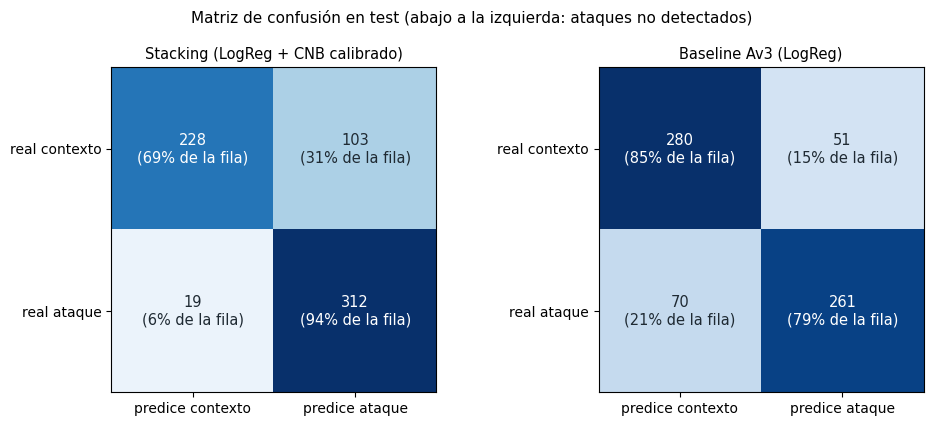

Falsos negativos (ataques no detectados): 19 contra 70 del baseline (-51)
Falsos positivos (falsas alarmas):        103 contra 51 del baseline (+52)
Por cada ataque no detectado que se evita se pagan 1.0 falsas alarmas más


In [36]:
# Gráfico 1. Matriz de confusión en test: modelo final contra el baseline del Avance 3
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, (nombre, pred) in zip(ejes, [(MODELO_FINAL, pred_final), (REFERENCIA, pred_ref)]):
    cm = confusion_matrix(yte, pred)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%} de la fila)", ha="center", va="center",
                    fontsize=10.5, color="white" if cm[i, j] > cm.max() * 0.6 else "#1f2a33")
    ax.set_xticks([0, 1], [f"predice {c}" for c in CLASES]); ax.set_yticks([0, 1], [f"real {c}" for c in CLASES])
    ax.set_title(nombre, fontsize=10.5)
plt.suptitle("Matriz de confusión en test (abajo a la izquierda: ataques no detectados)", fontsize=11)
plt.tight_layout(); plt.show()

(vn, fp), (fn, vp) = confusion_matrix(yte, pred_final)
(vn_r, fp_r), (fn_r, vp_r) = confusion_matrix(yte, pred_ref)
print(f"Falsos negativos (ataques no detectados): {fn} contra {fn_r} del baseline ({fn - fn_r:+d})")
print(f"Falsos positivos (falsas alarmas):        {fp} contra {fp_r} del baseline ({fp - fp_r:+d})")
if fn < fn_r and fp > fp_r:
    print(f"Por cada ataque no detectado que se evita se pagan {(fp - fp_r) / (fn_r - fn):.1f} falsas alarmas más")

# Uso de IA: Claude revisó su funcionamiento y corrigió errores de sintaxis.
# El equipo se encargó de la interpretación.

**Interpretación**

La matriz cuenta los aciertos y errores del modelo en test. La celda de abajo a la izquierda son los **falsos negativos** (oraciones de ataque que el modelo marcó como contexto), que es el error más costoso para el negocio, porque un ataque no detectado no llega al analista. La celda de arriba a la derecha son los **falsos positivos** (falsas alarmas), que solo cuestan tiempo de revisión.

- El Stacking detecta 312 de los 331 ataques (94 %) y deja pasar 19 (6 %), contra 70 (21 %) del baseline: **evita 51 ataques no detectados**.
- A cambio genera 103 falsas alarmas contra 51 del baseline (**52 más**), es decir, 1 falsa alarma por cada ataque que deja de perderse. Es un intercambio favorable si un ataque no detectado cuesta más que revisar una oración de más.
- Si bien los errores quedan repartidos de forma dispareja entre las dos clases (6 % de los ataques y 31 % del contexto), el modelo final corrige justo el error que más puede perjudicar al negocio, mientras que el baseline se equivoca más con los ataques (21 %) que con el contexto (15 %).

Como dato extra, previamente se ejecutó el código de las gráficas con el mismo modelo pero con el umbral default (0.5) y se encontró que tenía 52 FN y 64 FP. Al cambiar el umbral a 0.325 (elegido con train) se evitaron 33 FN con un costo de 39 FP más (≈ 1.2 FP por cada uno).

### Gráfico 2. Curva ROC

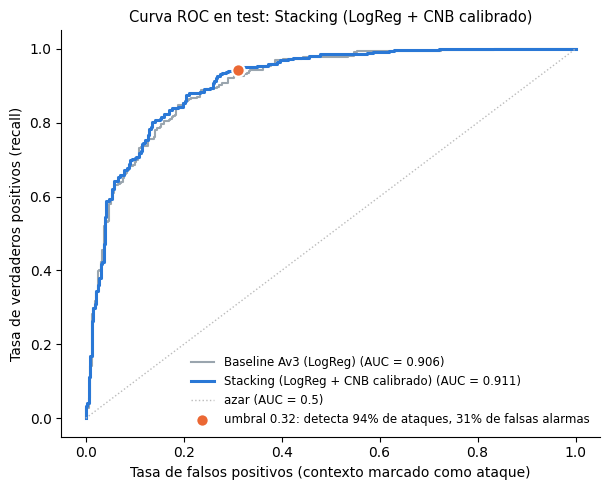

Para detectar 80% de los ataques, el modelo marca como ataque 14% de las oraciones de contexto
Para detectar 90% de los ataques, el modelo marca como ataque 26% de las oraciones de contexto
Para detectar 95% de los ataques, el modelo marca como ataque 32% de las oraciones de contexto


In [37]:
# Gráfico 2. Curva ROC en test: qué tan bien separa el modelo las dos clases, con cualquier umbral
fig, ax = plt.subplots(figsize=(6.2, 5))
for nombre, p, color, lw in [(REFERENCIA, p_ref, GRIS, 1.5), (MODELO_FINAL, p_final, AZUL, 2.2)]:
    fpr, tpr, _ = roc_curve(yte, p)
    ax.plot(fpr, tpr, color=color, lw=lw, label=f"{nombre} (AUC = {roc_auc_score(yte, p):.3f})")
ax.plot([0, 1], [0, 1], ls=":", color="#bbb", lw=1, label="azar (AUC = 0.5)")

# Punto de operación: dónde queda el modelo final con el umbral elegido
(vn, fp), (fn, vp) = confusion_matrix(yte, pred_final)
ax.scatter(fp / (fp + vn), vp / (vp + fn), s=80, color=NARANJA, edgecolors="white", lw=1.5, zorder=3,
           label=f"umbral {UMBRAL_FINAL:.2f}: detecta {vp / (vp + fn):.0%} de ataques, {fp / (fp + vn):.0%} de falsas alarmas")
ax.set_xlabel("Tasa de falsos positivos (contexto marcado como ataque)")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title(f"Curva ROC en test: {MODELO_FINAL}", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); estilo(ax)
plt.tight_layout(); plt.show()

# Cuántas falsas alarmas cuesta llegar a cierto recall (lectura descriptiva; el umbral NO se elige en test)
fpr, tpr, _ = roc_curve(yte, p_final)
for meta in [0.80, 0.90, 0.95]:
    print(f"Para detectar {meta:.0%} de los ataques, el modelo marca como ataque {fpr[np.argmax(tpr >= meta)]:.0%} de las oraciones de contexto")

# Uso de IA: Claude revisó su funcionamiento y corrigió errores.
# El equipo verificó el umbral establecido y realizó el análisis.

**Interpretación**

La curva ROC muestra, para todos los umbrales posibles, qué proporción de ataques se detecta (eje vertical) contra qué proporción de oraciones de contexto se marca por error (eje horizontal). Un modelo perfecto sube pegado a la esquina superior izquierda (AUC = 1) y uno al azar sigue la diagonal (AUC = 0.5).

- El Stacking tiene **AUC = 0.911**, contra 0.906 del baseline. Las dos curvas casi se superponen: el ensamble **no separa mucho mejor las clases**, lo que confirma el hallazgo de la sección 3 (los modelos ordenan casi igual de bien y el techo lo ponen las representaciones probadas).
- Lo que sí cambia es **dónde opera** el modelo: con el umbral de 0.325, el punto naranja queda en 94 % de ataques detectados con 31 % de falsas alarmas, un punto más arriba y a la derecha que el baseline sobre prácticamente la misma curva.
- La curva se aplana arriba de 0.85: para detectar 90 % de los ataques habría que aceptar 26 % de falsas alarmas, y para 95 %, 32 %. Llegar a recalls muy altos se paga caro, y ese punto se debe acordar con el cliente (elegido con train, nunca con test).

### Gráfico 3. Curva precisión-recall

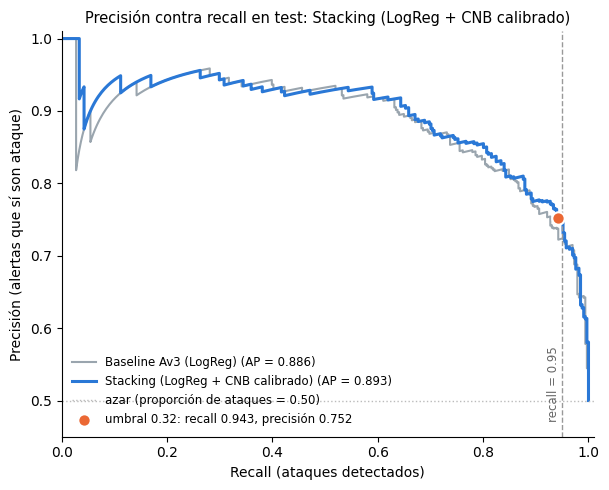

Con recall ≥ 0.80, la mejor precisión posible en test es 0.855
Con recall ≥ 0.90, la mejor precisión posible en test es 0.777
Con recall ≥ 0.95, la mejor precisión posible en test es 0.750


In [38]:
# Gráfico 3. Curva precisión-recall en test: qué precisión se paga por cada nivel de recall
fig, ax = plt.subplots(figsize=(6.2, 5))
for nombre, p, color, lw in [(REFERENCIA, p_ref, GRIS, 1.5), (MODELO_FINAL, p_final, AZUL, 2.2)]:
    prec, rec, _ = precision_recall_curve(yte, p)
    ax.plot(rec, prec, color=color, lw=lw, label=f"{nombre} (AP = {average_precision_score(yte, p):.3f})")
ax.axhline(yte.mean(), ls=":", color="#bbb", lw=1, label=f"azar (proporción de ataques = {yte.mean():.2f})")
ax.axvline(META_RECALL, color="#999", ls="--", lw=1)
ax.text(META_RECALL - 0.005, 0.47, f"recall = {META_RECALL}", rotation=90, ha="right", va="bottom", color="#666", fontsize=8.5)

# Punto de operación con el umbral elegido
r_op, p_op = recall_score(yte, pred_final), precision_score(yte, pred_final)
ax.scatter(r_op, p_op, s=80, color=NARANJA, edgecolors="white", lw=1.5, zorder=3,
           label=f"umbral {UMBRAL_FINAL:.2f}: recall {r_op:.3f}, precisión {p_op:.3f}")
ax.set_xlabel("Recall (ataques detectados)"); ax.set_ylabel("Precisión (alertas que sí son ataque)")
ax.set_xlim(0, 1.01); ax.set_ylim(0.45, 1.01)
ax.set_title(f"Precisión contra recall en test: {MODELO_FINAL}", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="lower left"); estilo(ax)
plt.tight_layout(); plt.show()

# Precisión máxima alcanzable en test con cada recall (descriptivo; el umbral NO se elige en test)
prec, rec, _ = precision_recall_curve(yte, p_final)
for meta in [0.80, 0.90, 0.95]:
    print(f"Con recall ≥ {meta:.2f}, la mejor precisión posible en test es {prec[:-1][rec[:-1] >= meta].max():.3f}")

# Uso de IA: Claude revisó su funcionamiento y corrigió errores.
# El equipo se aseguró de que se respetara el umbral elegido y redactó
# la interpretación.

**Interpretación**

Esta curva responde la pregunta práctica del analista: si quiero detectar cierta proporción de ataques (recall), ¿qué proporción de las alertas serán ataques de verdad (precisión)? La línea punteada (0.50) es lo que lograría un clasificador al azar, porque test tiene la mitad de oraciones de ataque.

- El Stacking tiene **AP = 0.893**, contra 0.886 del baseline: otra vez una mejora pequeña, con las curvas casi encimadas.
- Con el umbral de 0.325 opera en **recall 0.943 y precisión 0.752**: 3 de cada 4 alertas son ataques reales.
- La precisión se mantiene arriba de 0.9 hasta un recall cercano a 0.7 y después cae de forma sostenida. Con recall ≥ 0.90 la mejor precisión posible es 0.777 y con recall ≥ 0.95 baja a 0.750: **una de cada cuatro alertas sería falsa**.
- Para el negocio, esto significa que pedir un recall de 0.95 (la meta usada en la sección 3) es alcanzable, pero obliga a revisar bastantes más falsas alarmas. Es una decisión de costo que debe confirmar el cliente y en la que se debe considerar la capacidad disponible (analistas).

### Gráfico 4. Importancia de palabras

Los ensambles (Voting y Stacking) combinan modelos con vocabularios distintos, así que no tienen un solo coeficiente o importancia por rasgo. Para que el gráfico funcione igual con cualquier modelo se usa **importancia por oclusión**: a cada oración de test se le quita una palabra y se mide cuánto cambia la probabilidad de ataque. Se promedia por palabra y solo se consideran palabras que aparecen en al menos 8 oraciones.

228 palabras, 6042 oraciones modificadas (12 s)


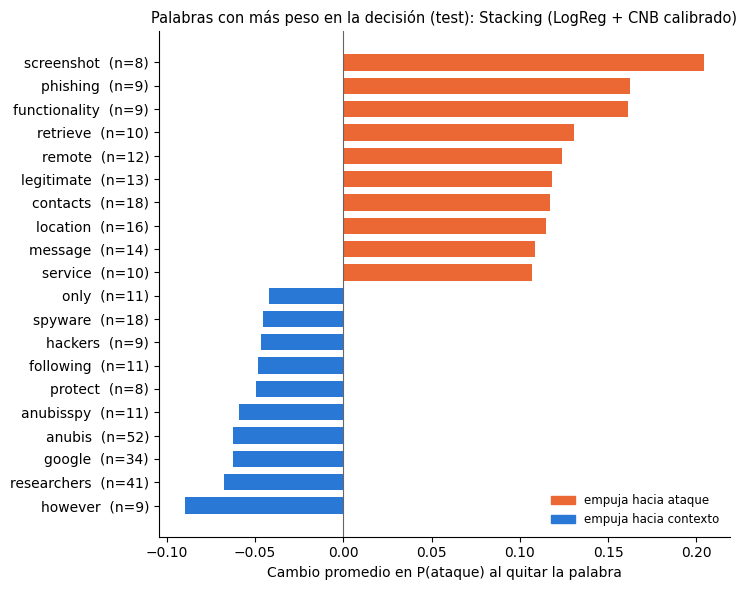

Pesos del meta-modelo (LogReg) sobre la probabilidad de cada modelo base: {'lr': 3.82, 'nb': 2.01} | intercepto: -2.73


In [39]:
# Gráfico 4. Importancia de palabras por oclusión (funciona igual con cualquier modelo, incluidos los ensambles):
# a cada oración de test se le quita una palabra y se mide cuánto cambia P(ataque).
#   efecto > 0: sin la palabra baja P(ataque)  -> la palabra empuja hacia "ataque"
#   efecto < 0: sin la palabra sube P(ataque)  -> la palabra empuja hacia "contexto"
import re
from collections import Counter

MIN_ORACIONES = 8      # solo palabras que aparecen en al menos 8 oraciones de test (menos ruido)
TOP = 10               # palabras por lado

palabra = re.compile(r"[a-z][a-z'-]+")
textos = te.text.tolist()
en_oracion = [set(palabra.findall(t.lower())) for t in textos]
frec = Counter(w for s in en_oracion for w in s)
candidatas = sorted(w for w, n in frec.items() if n >= MIN_ORACIONES)

# Se arman todas las oraciones modificadas y se predicen de una sola vez
modificadas, quien = [], []
for w in candidatas:
    patron = re.compile(rf"(?<![A-Za-z]){re.escape(w)}(?![A-Za-z])", re.IGNORECASE)
    for i, s in enumerate(en_oracion):
        if w in s:
            modificadas.append(re.sub(r"\s+", " ", patron.sub("", textos[i])).strip())
            quien.append((w, i))
t0 = time.perf_counter()
p_sin = modelo_final.predict_proba(modificadas)[:, 1]
print(f"{len(candidatas)} palabras, {len(modificadas)} oraciones modificadas ({time.perf_counter() - t0:.0f} s)")

ef = pd.DataFrame(quien, columns=["palabra", "i"]).assign(efecto=p_final[[i for _, i in quien]] - p_sin)
imp = ef.groupby("palabra")["efecto"].agg(["mean", "size"]).rename(columns={"mean": "efecto", "size": "oraciones"})
sel = pd.concat([imp.nlargest(TOP, "efecto"), imp.nsmallest(TOP, "efecto")]).sort_values("efecto")

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh([f"{w}  (n={n})" for w, n in zip(sel.index, sel["oraciones"])], sel["efecto"],
        color=[NARANJA if v > 0 else AZUL for v in sel["efecto"]], height=0.7)
ax.axvline(0, color="#666", lw=0.8)
ax.set_xlabel("Cambio promedio en P(ataque) al quitar la palabra")
ax.set_title(f"Palabras con más peso en la decisión (test): {MODELO_FINAL}", fontsize=10.5)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=NARANJA), plt.Rectangle((0, 0), 1, 1, color=AZUL)],
          labels=["empuja hacia ataque", "empuja hacia contexto"], frameon=False, fontsize=8.5, loc="lower right")
estilo(ax); plt.tight_layout(); plt.show()

# En stacking y voting, además: cuánto pesa cada modelo base en la decisión final
if hasattr(modelo_final, "final_estimator_"):
    pesos = modelo_final.final_estimator_.coef_[0]
    print("Pesos del meta-modelo (LogReg) sobre la probabilidad de cada modelo base:",
          {n: round(float(c), 2) for (n, _), c in zip(modelo_final.estimators, pesos)},
          "| intercepto:", round(float(modelo_final.final_estimator_.intercept_[0]), 2))
elif hasattr(modelo_final, "voting"):
    print("Voting suave: cada modelo base pesa lo mismo (promedio simple de probabilidades)")

# Uso de IA: Claude revisó su funcionamiento y corrigió errores

**Interpretación**

Las barras naranjas son palabras cuya presencia sube la probabilidad de ataque (al quitarlas, baja), y las azules, palabras que la bajan. Entre paréntesis está el número de oraciones de test donde aparece cada una.

- **Hacia ataque** aparecen verbos y objetos de lo que hace el malware en el dispositivo: *screenshot, retrieve, remote, contacts, location, message, functionality, phishing*. El modelo aprendió que una oración de ataque describe una **acción o capacidad** (tomar capturas, robar contactos, obtener la ubicación, enviar mensajes).
- **Hacia contexto** aparecen palabras del lenguaje del reporte: *however, researchers, google, protect, following*, y nombres de familias como *anubis* y *anubisspy*. Llama la atención que *spyware* y *hackers* empujen hacia contexto: una posible explicación es que el modelo distingue entre oraciones que **hablan sobre** el malware (quién lo descubrió, cómo se llama, cómo protegerse) y oraciones que **describen lo que hace**, que es justo la diferencia que se busca.
- **Riesgo de generalización:** los nombres de familias (*anubis*, en 52 oraciones) son propios de este conjunto de datos; en otros reportes (por ejemplo, el de Kaspersky) aparecerán familias distintas. Muchas palabras aparecen en pocas oraciones (8 a 18), por lo que su efecto exacto tiene margen de error.
- En el Stacking, el meta-modelo da un peso de 3.82 a la probabilidad de la LogReg y de 2.01 a la del Complement NB: la decisión se apoya más en la LogReg.
- La oclusión trabaja con palabras completas, por lo que no captura patrones de formato como el trozo ' — ' que se discutió en la sección 3.

# Conclusión general

Se probaron seis ensambles (dos heterogéneos y cuatro homogéneos) con la idea de aprovechar las fortalezas de distintos modelos y compensar sus debilidades.

Se encontró que la mejora en F1 fue pequeña y no concluyente, mas no una mejora significativa: el Stacking, el mejor, superó a la LogReg por solo 0.005 en validación cruzada. Donde se observó un cambio fue el perfil de errores: con el umbral ajustado, en test el recall pasó de 0.789 a 0.943 (con respecto al baseline) y los falsos negativos de 70 a 19, a cambio de 52 falsas alarmas más. Con esto presente, se plantea que la mejora en recall realmente viene del umbral, no necesariamente del ensamble.

Una posible explicación de que el ensamble aporte poco es que los modelos fallan en oraciones parecidas, por lo que combinarlos aporta poca diversidad. Esto es una hipótesis, no un resultado comprobado.

Para saber qué tan bien predice el modelo con datos que no vio, test se usó una sola vez por modelo, y la elección se hizo antes con validación cruzada y dev. Para el Stacking el umbral se fijó con train, y se revisó y comparó en dev; los resultados en test con 0.5 ya se habían observado antes, y aquí se reportan con 0.325.

En test, el modelo final obtuvo F1 0.836, recall 0.943 y precisión 0.752. Estas cifras deben leerse con cautela porque vienen de una sola partición.

El modelo final es el Stacking (LogReg y Complement NB calibrado) con umbral 0.325, elegido en train para un recall cercano a 0.95. La elección es provisional y está condicionada a la confirmación del cliente sobre la meta de recall y el costo de un falso negativo frente a una falsa alarma.

Quedan pendientes la confirmación con el cliente y la evaluación en el reporte de Kaspersky (requiere sus etiquetas).




> Uso de IA: Se redactó un borrador, acto seguido se le dio a Claude para revisión de sintaxis y ortografía. El equipo lo revisó, y verificó las cifras contra las salidas.

